# [GSE126468](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE126468)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2021-03-16
> - Modified: 2025-05-03

# 1. Experimental Design

> The chromosomal protein SMCHD1 regulates DNA methylation by antagonizing TET proteins.
> - Zhijun Huang et al. ,The chromosomal protein SMCHD1 regulates DNA methylation and the 2c-like state of embryonic stem cells by antagonizing TET proteins.Sci. Adv.7,eabb9149(2021).DOI:10.1126/sciadv.abb9149.
> - Swift, Accel-NGS Methyl-Seq DNA Library Kit (Swift Biosciences, 30024), and Zymo’s EZ DNA Methylation-Lightning kit (Zymo Research, D5030)
> - Illumina HiSeq X Ten, PE150
> - Bismark-Bowtie2
> - mm9


| Sample | Cell | Organism | Strain | Tissue | Genotype | Replicate |
| - | - | - | - | - | - | - |
| WT | mESC | Mus musculus | J1 | Embryonic stem cells | Wild Type | rep1~3 |
| KO | mESC | Mus musculus | J1 | Embryonic stem cells | Smchd1 KO | rep1~3 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))
suppressPackageStartupMessages(library(ggpubr))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/wgbs_Mm_mESC_Smchd1_GSE126468"

In [3]:
suppressPackageStartupMessages(library(BSgenome.Mmusculus.UCSC.mm9))
genome <- BSgenome.Mmusculus.UCSC.mm9

suppressPackageStartupMessages(library(TxDb.Mmusculus.UCSC.mm9.knownGene))
txdb <- TxDb.Mmusculus.UCSC.mm9.knownGene

# 2. Import Data

## 1). Import Bismark Cov

In [4]:
# Load Bismark coverage file as GRanges
load_bismark_cov <- function(
    file, cov = 5, keepStandardChr = TRUE, dropSex = TRUE, dropMito = TRUE) {

    gr <- data.table::fread(
        file, header = FALSE, sep = "\t", 
        col.names = c("chr", "start", "end", "meth", "numCs", "numTs")) |>
        dplyr::filter((numCs + numTs) >= cov) |>
        GRanges()

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    return(gr)
}

In [5]:
file_pattern <- "^GSM\\d+_(.*)\\.bismark\\.cov\\.gz$"

cov_files <- file.path(data_dir, "00_geo") |>
    list.files(pattern = file_pattern, full.names = TRUE) |>
    set_names(~ sub(file_pattern, "\\1", basename(.x)))

paste(names(cov_files), basename(cov_files), sep = ": ") |> cat(sep = "\n")

mESC_Smchd1_WT_rep1: GSM3602177_mESC_Smchd1_WT_rep1.bismark.cov.gz
mESC_Smchd1_WT_rep2: GSM3602178_mESC_Smchd1_WT_rep2.bismark.cov.gz
mESC_Smchd1_WT_rep3: GSM3602179_mESC_Smchd1_WT_rep3.bismark.cov.gz
mESC_Smchd1_KO_rep1: GSM3602180_mESC_Smchd1_KO_rep1.bismark.cov.gz
mESC_Smchd1_KO_rep2: GSM3602181_mESC_Smchd1_KO_rep2.bismark.cov.gz
mESC_Smchd1_KO_rep3: GSM3602182_mESC_Smchd1_KO_rep3.bismark.cov.gz


In [6]:
cov_list <- lapply(cov_files, cov = 0, load_bismark_cov, dropSex = FALSE)

names(cov_list)

[1] "mESC_Smchd1_WT_rep1" "mESC_Smchd1_WT_rep2" "mESC_Smchd1_WT_rep3"
[4] "mESC_Smchd1_KO_rep1" "mESC_Smchd1_KO_rep2" "mESC_Smchd1_KO_rep3"

In [7]:
coldata <- data.frame(sample = names(cov_list)) |>
    separate(
        sample, into = c("Cell", "Gene", "Group", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Group = factor(Group, levels = c("WT", "KO")),
        Replicate = factor(Replicate)) |>
    column_to_rownames("sample")

coldata

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
mESC_Smchd1_WT_rep1,mESC,Smchd1,WT,rep1
mESC_Smchd1_WT_rep2,mESC,Smchd1,WT,rep2
mESC_Smchd1_WT_rep3,mESC,Smchd1,WT,rep3
mESC_Smchd1_KO_rep1,mESC,Smchd1,KO,rep1
mESC_Smchd1_KO_rep2,mESC,Smchd1,KO,rep2
mESC_Smchd1_KO_rep3,mESC,Smchd1,KO,rep3


## 2). CpG Aggregation

> Strand-aware CpG methylation aggregation
> - CpG methylation calls from the Watson and Crick strands were combined to produce unified CpG-level profiles. For each CpG site, strand-specific methylated (C) and unmethylated (T) read counts were summed, and methylation levels were recalculated as the ratio of total methylated reads to total coverage across both strands. This aggregation strategy provides a single, strand-independent representation of CpG methylation for downstream analysis.

In [8]:
# Extracting CpG sites from genome
CpGs <- lapply(seqnames(genome), function(chr) {
    seq <- getSeq(genome, chr)
    pos <- Biostrings::matchPattern("CG", seq)
    GRanges(chr, IRanges(start = start(pos), end = end(pos)), strand = "+")
}) |>
    GRangesList() |> unlist() |>
    GenomeInfoDb::keepStandardChromosomes(pruning.mode = "coarse") |>
    GenomeInfoDb::dropSeqlevels("chrM", pruning.mode = "coarse")

CpGs

GRanges object with 21342492 ranges and 0 metadata columns:
             seqnames          ranges strand
                <Rle>       <IRanges>  <Rle>
         [1]     chr1 3000574-3000575      +
         [2]     chr1 3000726-3000727      +
         [3]     chr1 3000901-3000902      +
         [4]     chr1 3001346-3001347      +
         [5]     chr1 3001394-3001395      +
         ...      ...             ...    ...
  [21342488]     chrY 2901854-2901855      +
  [21342489]     chrY 2902114-2902115      +
  [21342490]     chrY 2902429-2902430      +
  [21342491]     chrY 2902453-2902454      +
  [21342492]     chrY 2902491-2902492      +
  -------
  seqinfo: 21 sequences from an unspecified genome; no seqlengths

In [9]:
aggregate_cpg_methylation <- function(input, cpg, cov = 5) {
    message("Aggregating methylation to CpG sites...")

    hits <- findOverlaps(cpg, input, ignore.strand = TRUE)

    if (length(hits) == 0) return(NULL)

    df <- data.table::data.table(
        cpg_idx = queryHits(hits),
        numCs = input$numCs[subjectHits(hits)],
        numTs = input$numTs[subjectHits(hits)])

    agg <- df[, .(numCs = sum(numCs), numTs = sum(numTs)), by = cpg_idx]
    agg <- agg[(numCs + numTs) >= cov]
    if (nrow(agg) == 0) return(NULL)

    result <- cpg[agg$cpg_idx]
    result$meth <- with(agg, numCs / (numCs + numTs) * 100)
    result$numCs <- agg$numCs
    result$numTs <- agg$numTs

    return(result)
}

In [10]:
meth_list <- lapply(cov_list, aggregate_cpg_methylation, cpg = CpGs, cov = 0)

meth_list[1]

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...



$mESC_Smchd1_WT_rep1
GRanges object with 20363484 ranges and 3 metadata columns:
             seqnames          ranges strand |      meth     numCs     numTs
                <Rle>       <IRanges>  <Rle> | <numeric> <integer> <integer>
         [1]     chr1 3000574-3000575      + |   86.9565        20         3
         [2]     chr1 3000726-3000727      + |   55.5556         5         4
         [3]     chr1 3000901-3000902      + |    0.0000         0         6
         [4]     chr1 3001346-3001347      + |   80.0000        12         3
         [5]     chr1 3001394-3001395      + |   87.5000        14         2
         ...      ...             ...    ... .       ...       ...       ...
  [20363480]     chrY 2901854-2901855      + |  73.59781       538       193
  [20363481]     chrY 2902114-2902115      + |   3.81471        14       353
  [20363482]     chrY 2902429-2902430      + |   7.14286         1        13
  [20363483]     chrY 2902453-2902454      + |  42.85714         3      

In [11]:
meth_list <- lapply(meth_list, function(x) {
    subset(x, (numCs + numTs) >= 5)
})

In [12]:
# Export bw files for visualization in IGV
lapply(names(meth_list), function(idx){
    gr <- meth_list[[idx]]
    mcols(gr)[["score"]] <- mcols(gr)[["meth"]]
    seqinfo(gr) <- seqinfo(genome)[seqlevels(gr)]
    export.bw(gr, file.path(data_dir, "00_geo", paste0(idx, ".bw")))
}) |> invisible()

# 3. Evaluate Library Quality

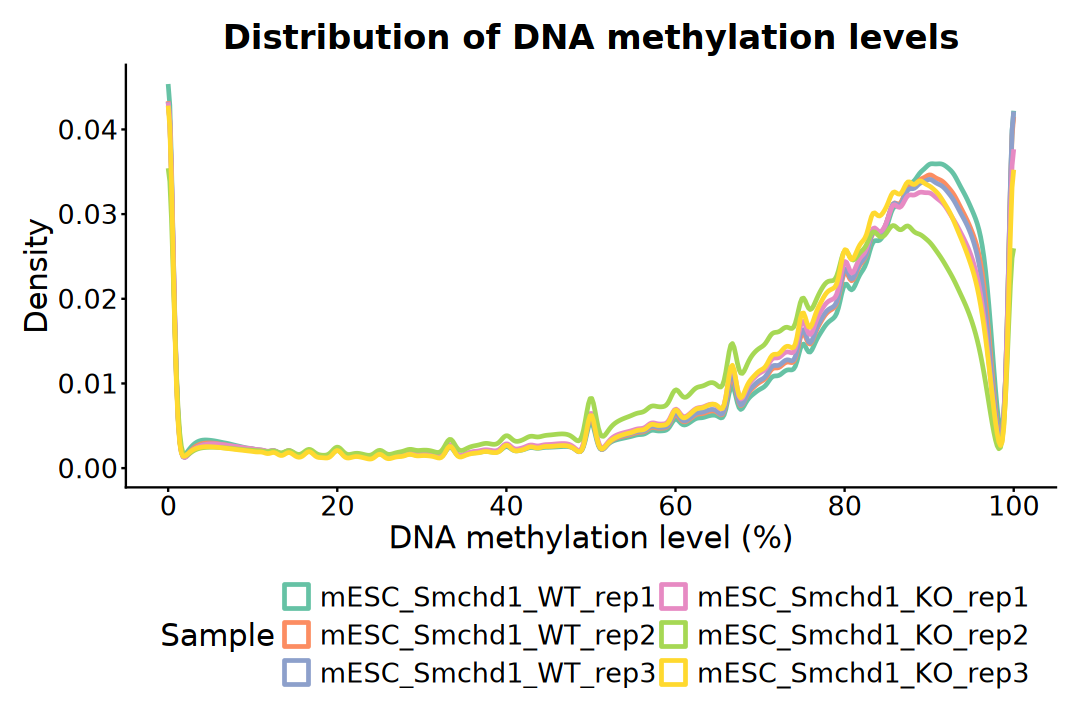

In [13]:
options(repr.plot.width = 9, repr.plot.height = 6)

map_df(meth_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    dplyr::select(sample, meth) |>
    dplyr::mutate(sample = factor(sample, levels = names(meth_list))) |>
    ggplot(aes(x = meth, color = sample)) +
    geom_density(linewidth = 1) +
    scale_x_continuous(breaks = seq(0, 100, 20)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 3)) +
    labs(
        title = "Distribution of DNA methylation levels",
        x = "DNA methylation level (%)", y = "Density", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

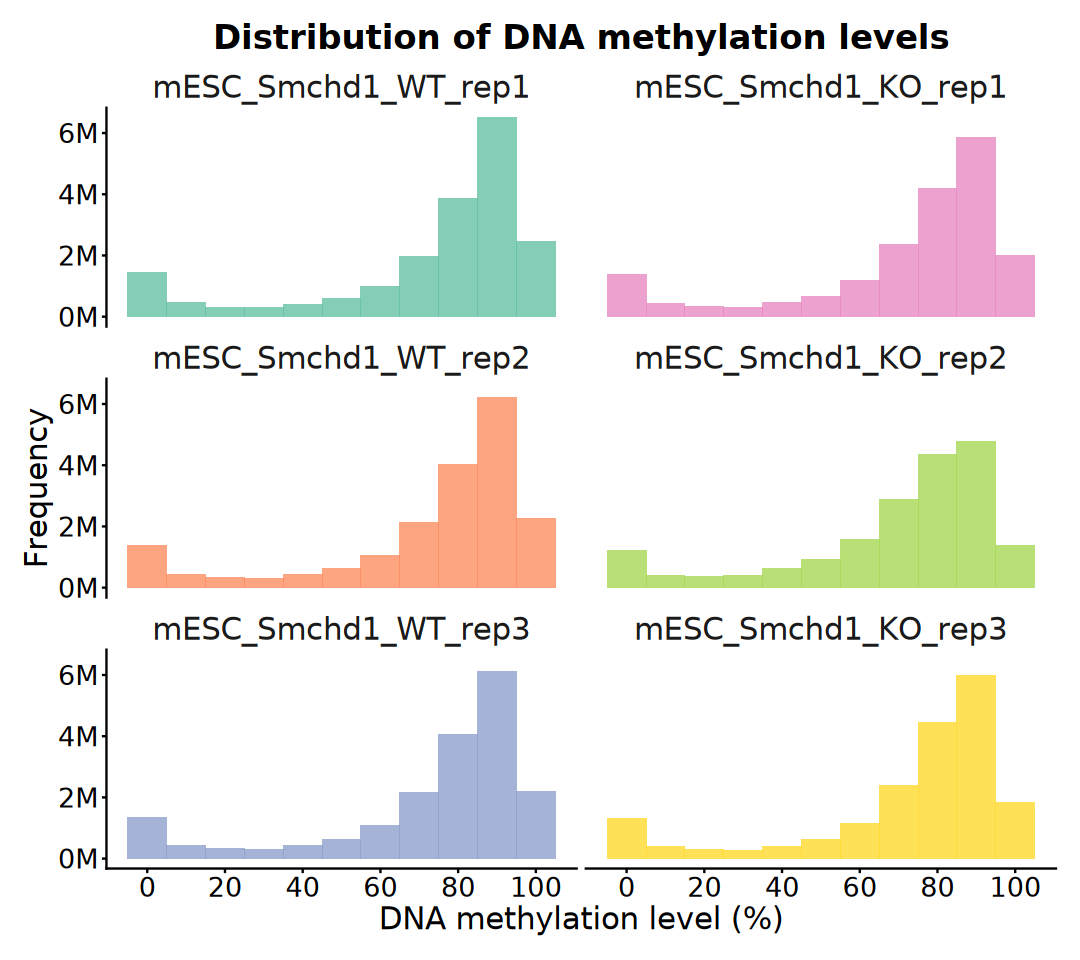

In [14]:
options(repr.plot.width = 9, repr.plot.height = 8)

map_df(meth_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    dplyr::select(sample, meth) |>
    dplyr::mutate(sample = factor(sample, levels = names(meth_list))) |>
    ggplot(aes(x = meth, fill = sample)) +
    geom_histogram(binwidth = 10, position = "identity", alpha = 0.8) +
    facet_wrap(~ sample, ncol = 2, dir = "v") +
    scale_x_continuous(breaks = seq(0, 100, 20)) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "Distribution of DNA methylation levels",
        x = "DNA methylation level (%)", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        strip.background = element_blank(),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

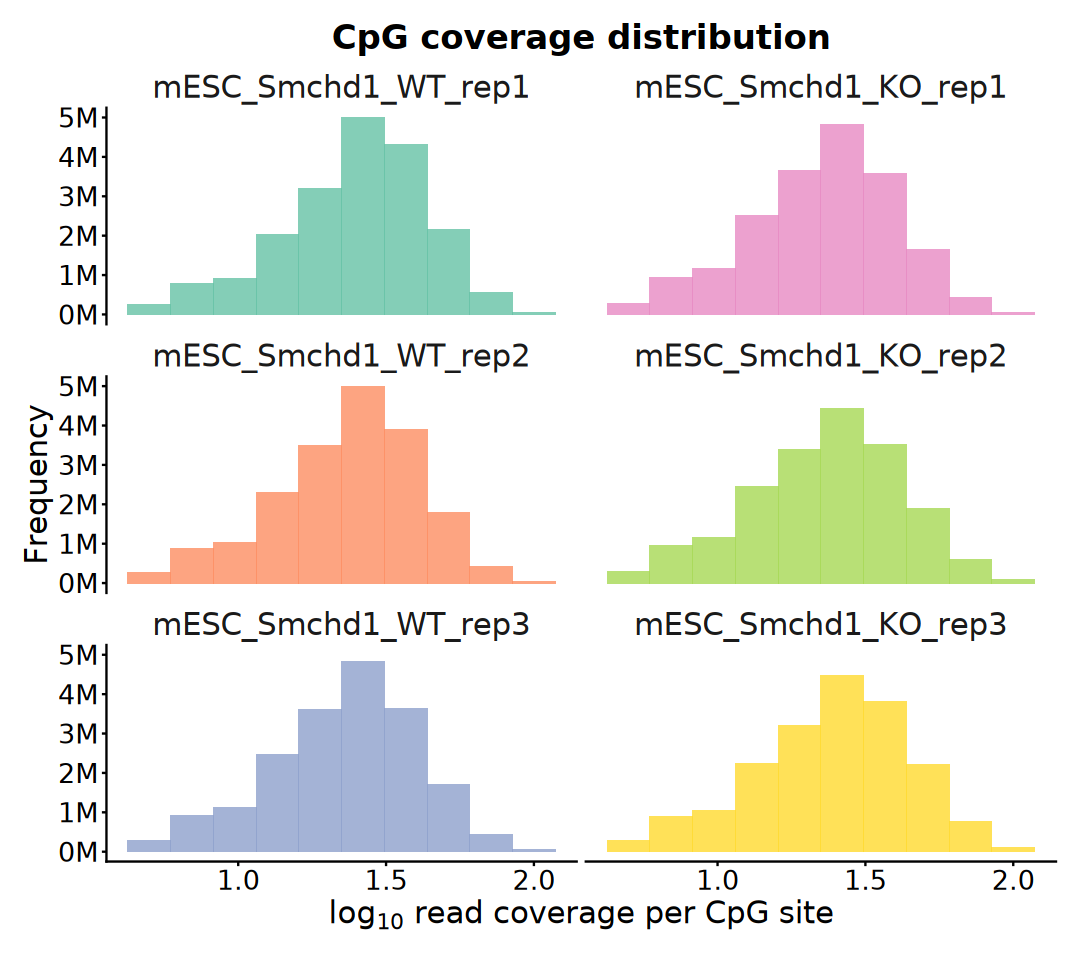

In [15]:
options(repr.plot.width = 9, repr.plot.height = 8)

map_df(meth_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    dplyr::mutate(coverage = numCs + numTs) |>
    dplyr::select(sample, coverage) |>
    dplyr::filter(coverage <= 100) |>
    dplyr::mutate(sample = factor(sample, levels = names(meth_list))) |>
    ggplot(aes(x = log10(coverage), fill = sample)) +
    geom_histogram(bins = 10, alpha = 0.8) +
    facet_wrap( ~ sample, ncol = 2, dir = "v") +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG coverage distribution",
        x = expression(log[10] ~ "read coverage per CpG site"),
        y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        strip.background = element_blank(),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 4. Global Methylation

## 1). Standard Plot

In [16]:
plot_df <- data.frame(
    sample = names(meth_list),
    number = sapply(meth_list, length),
    mean = sapply(meth_list, \(gr) mean(mcols(gr)$meth))) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    column_to_rownames("sample")

plot_df

,number,mean,Cell,Gene,Group,Replicate
,<int>,<dbl>,<chr>,<chr>,<fct>,<fct>
mESC_Smchd1_WT_rep1,19277848,72.94389,mESC,Smchd1,WT,rep1
mESC_Smchd1_WT_rep2,19129206,72.66887,mESC,Smchd1,WT,rep2
mESC_Smchd1_WT_rep3,19087635,72.52257,mESC,Smchd1,WT,rep3
mESC_Smchd1_KO_rep1,19115120,71.70500,mESC,Smchd1,KO,rep1
mESC_Smchd1_KO_rep2,18865665,69.41777,mESC,Smchd1,KO,rep2
mESC_Smchd1_KO_rep3,19089646,72.45438,mESC,Smchd1,KO,rep3


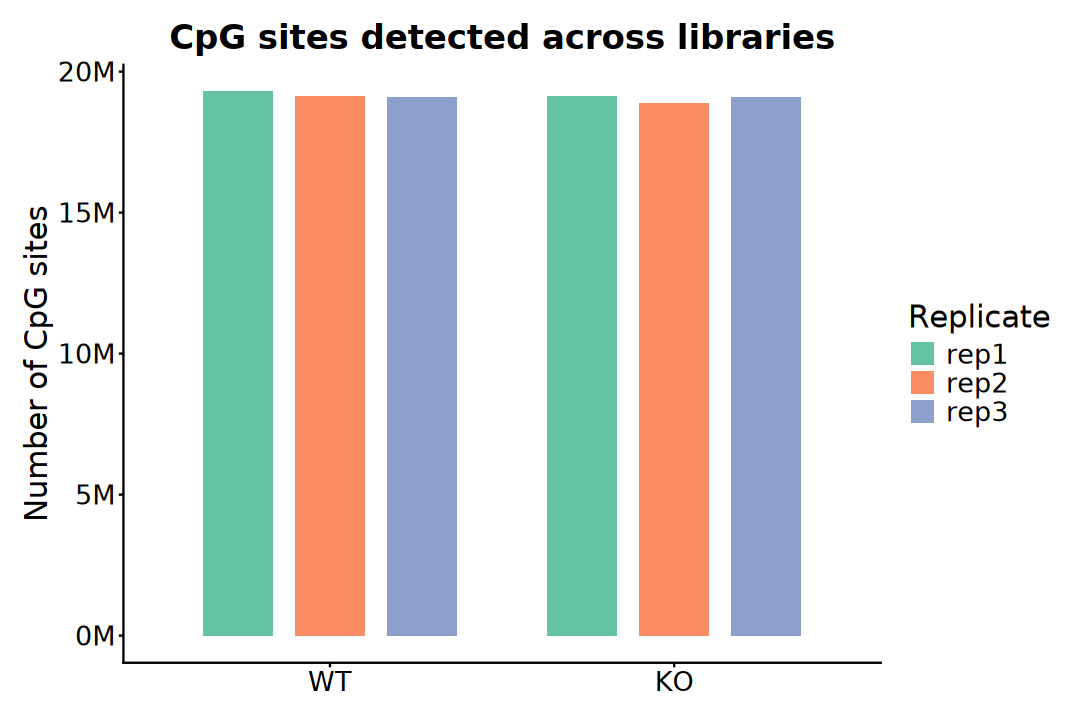

In [17]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = number, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity", 
        position = position_dodge(width = 0.8), 
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG sites detected across libraries", 
        x = NULL, y = "Number of CpG sites") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

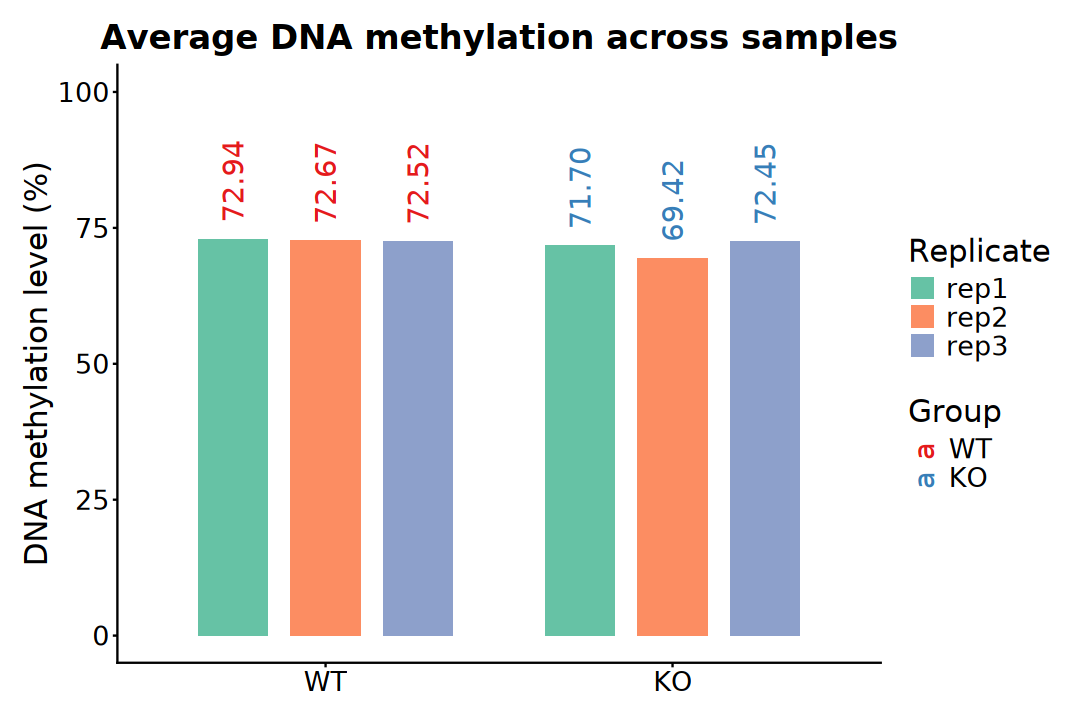

In [18]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = mean, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    geom_text(
        aes(color = Group, label = sprintf("%.2f", round(mean, 2))),
        position = position_dodge(width = 0.8),
        angle = 90, vjust = 0.5, hjust = -0.2, size = 6) +
    coord_cartesian(ylim = c(0, 100)) +
    scale_color_brewer(palette = "Set1") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "Average DNA methylation across samples",
        x = NULL, y = "DNA methylation level (%)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

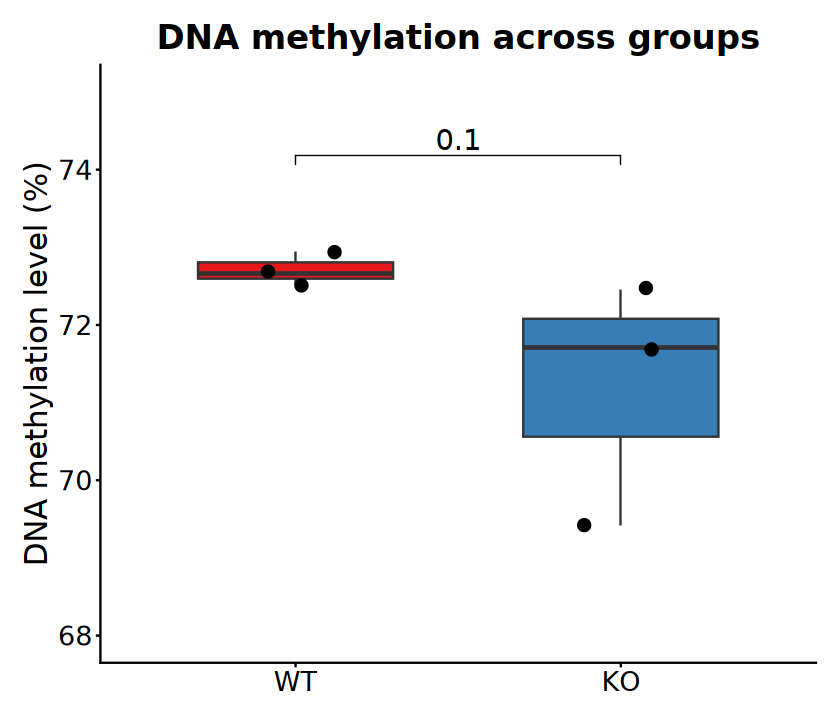

In [19]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = mean, fill = Group)) +
    geom_boxplot(width = 0.6, linewidth = 0.5, outlier.shape = NA) +
    geom_jitter(width = 0.15, size = 3, color = "black") +
    stat_compare_means(
        comparisons = list(c("KO", "WT")), method = "wilcox.test", 
        label = "p.format", size = 6, label.y = 74) +
    coord_cartesian(ylim = c(68, 75)) +
    scale_fill_brewer(palette = "Set1") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "DNA methylation across groups",
        x = NULL, y = "DNA methylation level (%)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [20]:
plot_df <- map_dfr(meth_list, ~ tibble(
    meth = mcols(.x)$meth), .id = "sample") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample")

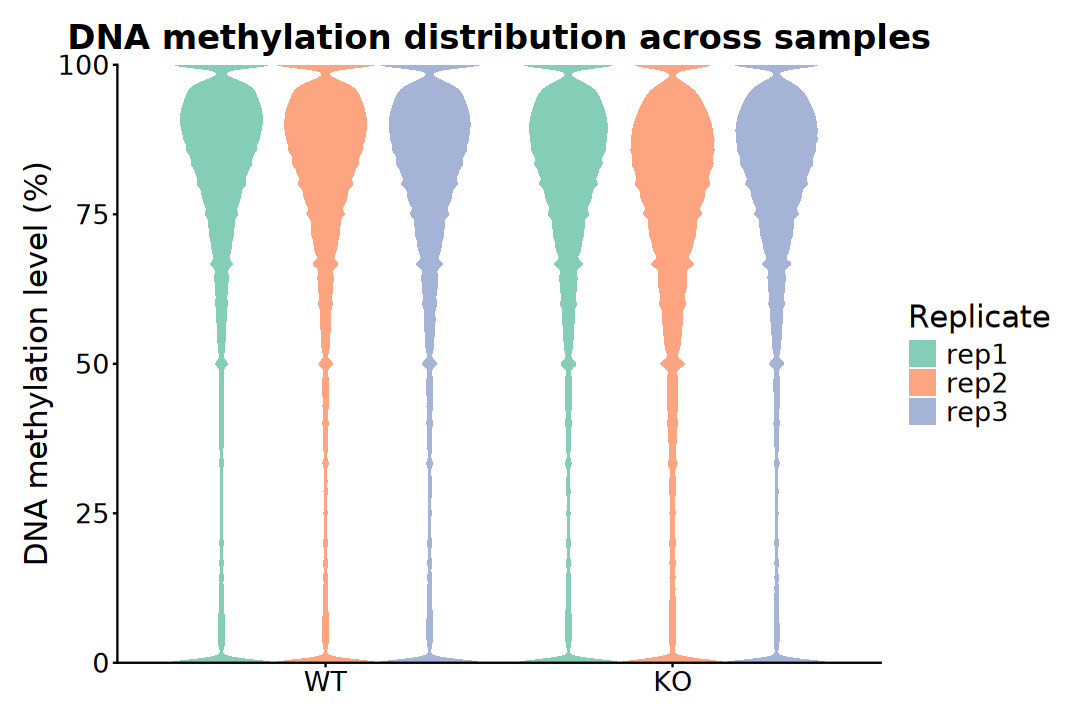

In [21]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = meth, fill = Replicate)) +
    geom_violin(trim = TRUE, scale = "width", color = NA, alpha = 0.8) +
    # geom_boxplot(
    #     width = 0.2, outlier.shape = NA, color = "grey50",
    #     position = position_dodge(width = 0.9)) +
    # stat_summary(
    #     fun = median, geom = "point", size = 2, color = "black",
    #     position = position_dodge(width = 0.9)) +
    labs(
        title = "DNA methylation distribution across samples",
        x = NULL, y = "DNA methylation level (%)") +
    scale_y_continuous(limits = c(0, 100), expand = c(0, 0)) +
    scale_fill_brewer(palette = "Set2") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). Density Scatter Plot

In [22]:
common_cpg <- Reduce(function(x, y) {
    x[findOverlaps(x, y, type = "equal") |> queryHits()]
}, meth_list) |> granges()

common_cpg

GRanges object with 18187735 ranges and 0 metadata columns:
             seqnames          ranges strand
                <Rle>       <IRanges>  <Rle>
         [1]     chr1 3000574-3000575      +
         [2]     chr1 3000726-3000727      +
         [3]     chr1 3001346-3001347      +
         [4]     chr1 3001394-3001395      +
         [5]     chr1 3001631-3001632      +
         ...      ...             ...    ...
  [18187731]     chrY 2901854-2901855      +
  [18187732]     chrY 2902114-2902115      +
  [18187733]     chrY 2902429-2902430      +
  [18187734]     chrY 2902453-2902454      +
  [18187735]     chrY 2902491-2902492      +
  -------
  seqinfo: 21 sequences from an unspecified genome; no seqlengths

In [23]:
meth_common <- lapply(meth_list, function(gr) {
    hits <- findOverlaps(common_cpg, gr, type = "equal")
    meth <- rep(NA_real_, length(common_cpg))
    meth[queryHits(hits)] <- gr$meth[subjectHits(hits)]
    meth
})

meth_common <- as.data.frame(meth_common)
names(meth_common) <- names(meth_list)

In [24]:
sample_pairs <- combn(names(meth_list), 2, simplify = FALSE)
sample_pairs <- Filter(function(pair) {
        r1 <- sub(".*_rep([0-9]+)$", "\\1", pair[1])
        r2 <- sub(".*_rep([0-9]+)$", "\\1", pair[2])
        r1 == r2}, sample_pairs)

sample_pairs

[[1]]
[1] "mESC_Smchd1_WT_rep1" "mESC_Smchd1_KO_rep1"

[[2]]
[1] "mESC_Smchd1_WT_rep2" "mESC_Smchd1_KO_rep2"

[[3]]
[1] "mESC_Smchd1_WT_rep3" "mESC_Smchd1_KO_rep3"

In [25]:
plot_list <- lapply(sample_pairs, function(pair) {
    ggplot(meth_common, aes(.data[[pair[1]]], .data[[pair[2]]])) +
        geom_bin2d(bins = 100) +
        geom_abline(
            slope = 1, intercept = 0, linetype = "dashed",
            color = "lightcoral", linewidth = 1) +
        scale_fill_gradientn(
            colors = viridis(256), trans = "log10", name = "Count (log10)") +
        coord_fixed() +
        labs(title = "DNA methylation comparison", x = pair[1], y = pair[2]) +
        theme_bw() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            legend.position = "right",
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
})

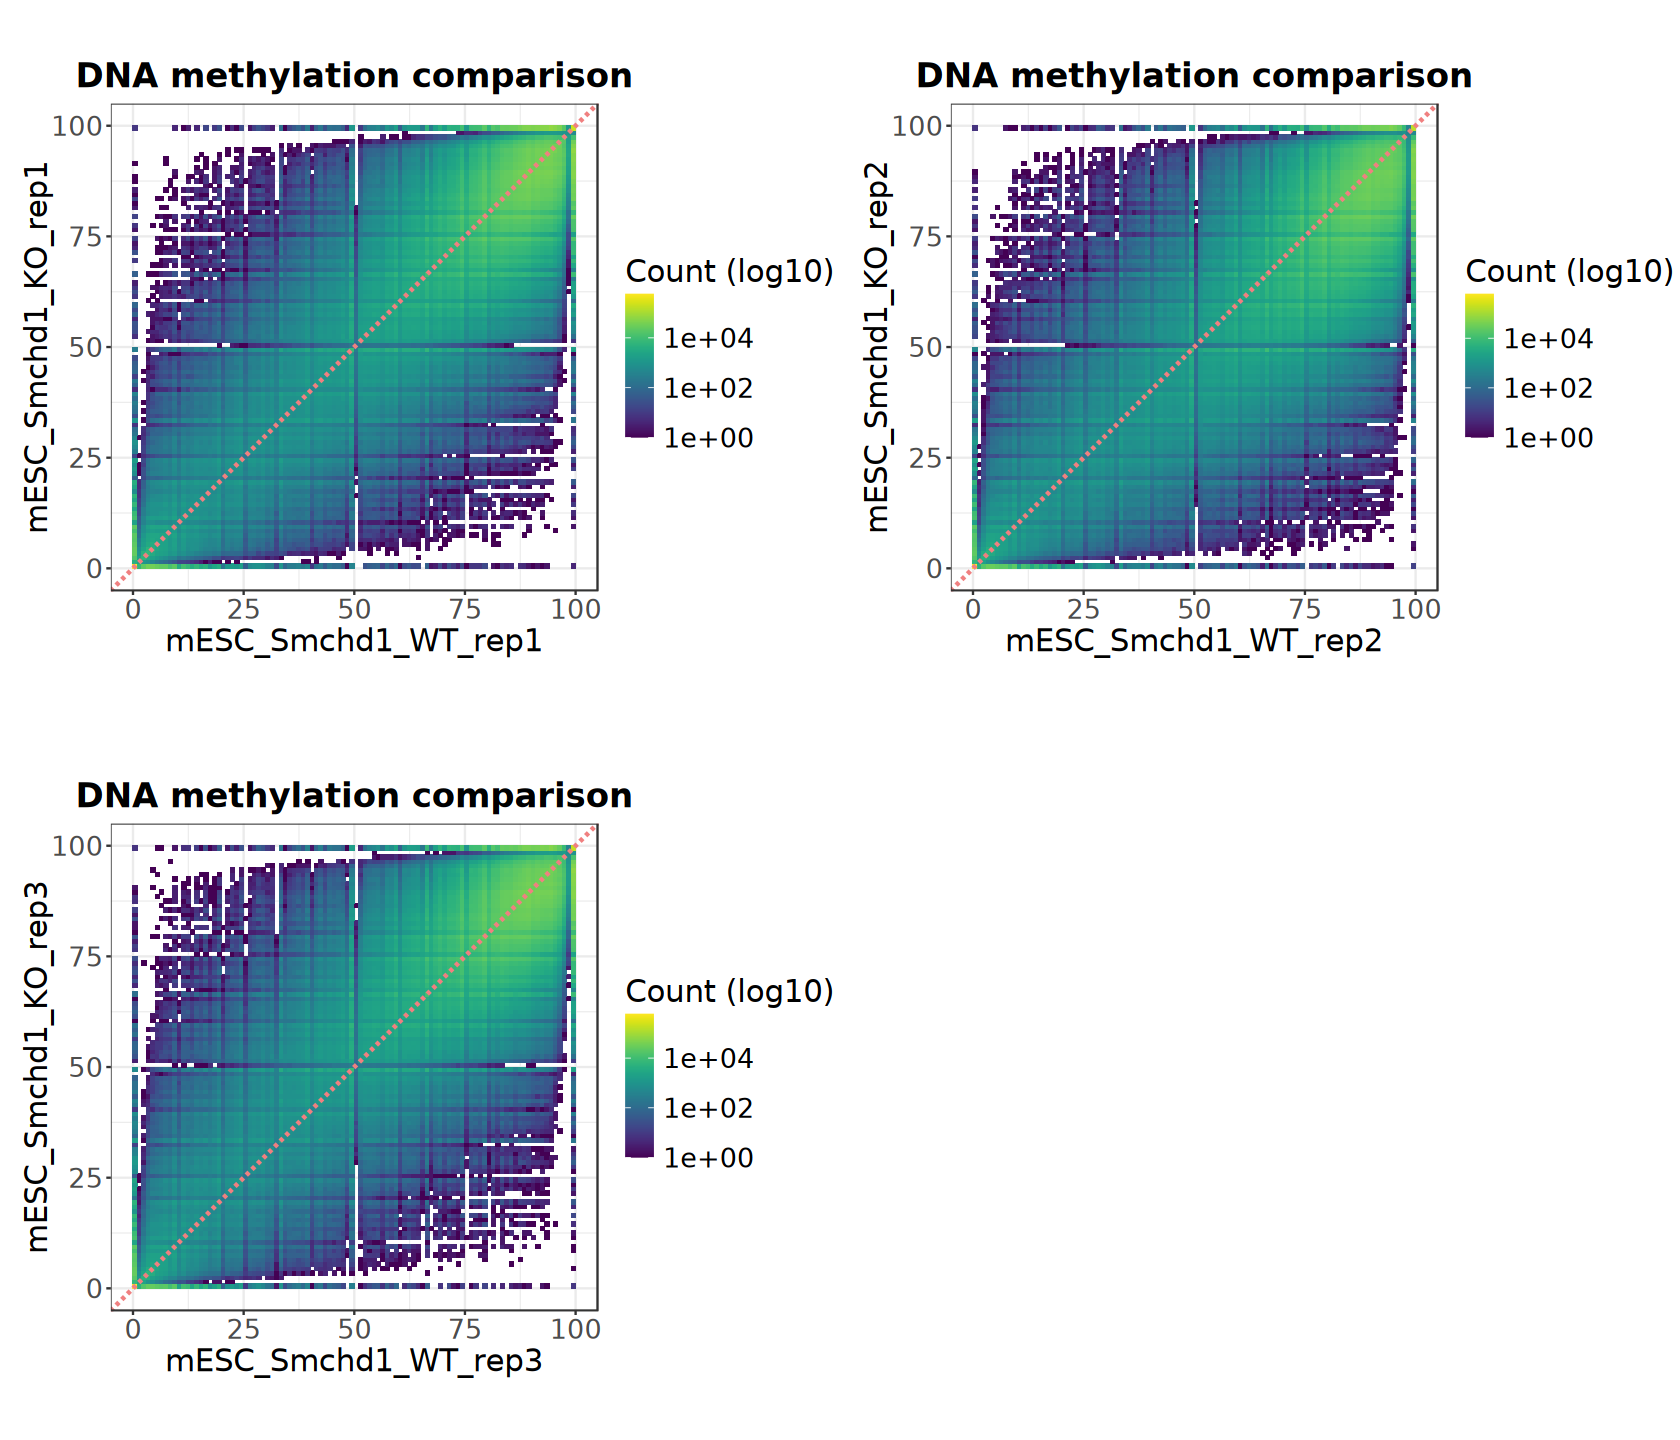

In [26]:
options(repr.plot.width = 14, repr.plot.height = 12)

plot_grid(plotlist = plot_list, nrow = 2, ncol = 2, byrow = TRUE)

In [27]:
plot_methylation_comparison <- function(plot_df, sample_x, sample_y) {
    # Linear regression
    fit <- lm(methy_y ~ methy_x, data = plot_df)

    # Spearman correlation
    cor_res <- cor.test(
        plot_df$methy_x, plot_df$methy_y, method = "spearman", exact = FALSE)

    # scatter plot
    smoothScatter(
        plot_df$methy_x, plot_df$methy_y,
        colramp = colorRampPalette(brewer.pal(9, "Blues")),
        xlab = sample_x, ylab = sample_y, cex = 0)
    abline(a = 0, b = 1, col = "darkblue", lty = 2, lwd = 3)
    abline(fit, col = "darkred", lty = 2, lwd = 3)
    legend(
        "topleft", lty = 2, lwd = 2, col = 'black', border = NA, 
        text.col = "black", box.col = NA, bg = NA,
        legend = c(
            paste0("Linear slope: ", round(coef(fit)[2], 2)),
            paste0("Spearman \u03c1: ", round(cor_res$estimate, 2)),
            paste0("P-value: ", format.pval(
                cor_res$p.value, digits = 2, eps = 1e-100))))
}

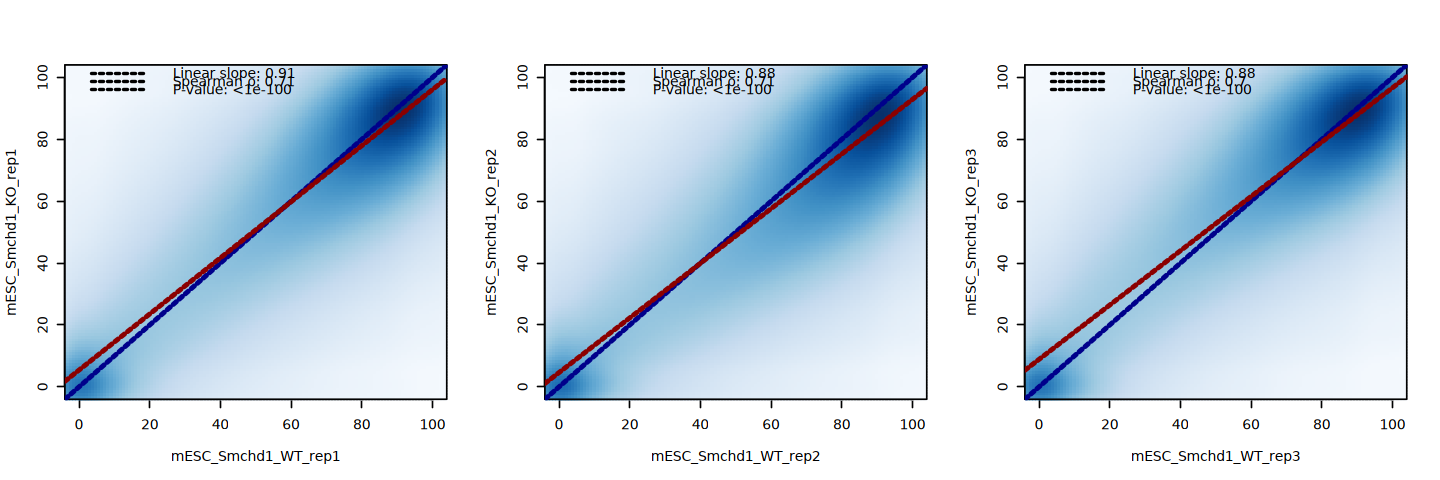

In [28]:
options(repr.plot.width = 12, repr.plot.height = 4)

par(mfrow = c(1, 3))

for (pair in sample_pairs) {
    plot_df <- data.frame(
        methy_x = meth_common[[pair[1]]],
        methy_y = meth_common[[pair[2]]])
    plot_methylation_comparison(plot_df, pair[1], pair[2])
}

## 3). Genomic Signal Plot

In [29]:
chr_idx <- "chr2"
chrom_sizes <- seqlengths(genome)[chr_idx]
bins <- tileGenome(
    seqlengths = chrom_sizes, tilewidth = 1e6,
    cut.last.tile.in.chrom = TRUE)
names(bins) <- floor((start(bins) + end(bins)) / 2)

In [30]:
bin_stats_list <- lapply(names(meth_list), function(idx) {
    gr <- meth_list[[idx]]
    gr <- gr[seqnames(gr) == chr_idx]
    hits <- findOverlaps(gr, bins, ignore.strand = TRUE)

    df <- data.table::data.table(
        bin_idx = subjectHits(hits),
        numCs = gr$numCs[queryHits(hits)],
        numTs = gr$numTs[queryHits(hits)])

    bin_stats <- df[, list(
        numCs = sum(numCs), numTs = sum(numTs)), by = bin_idx]
    bin_stats[, meth := numCs / (numCs + numTs) * 100]

    result <- bins[bin_stats$bin_idx]
    result$meth <- bin_stats$meth
    result$numCs <- bin_stats$numCs
    result$numTs <- bin_stats$numTs
    result$sample <- idx
    names(result) <- NULL
    return(result)
})

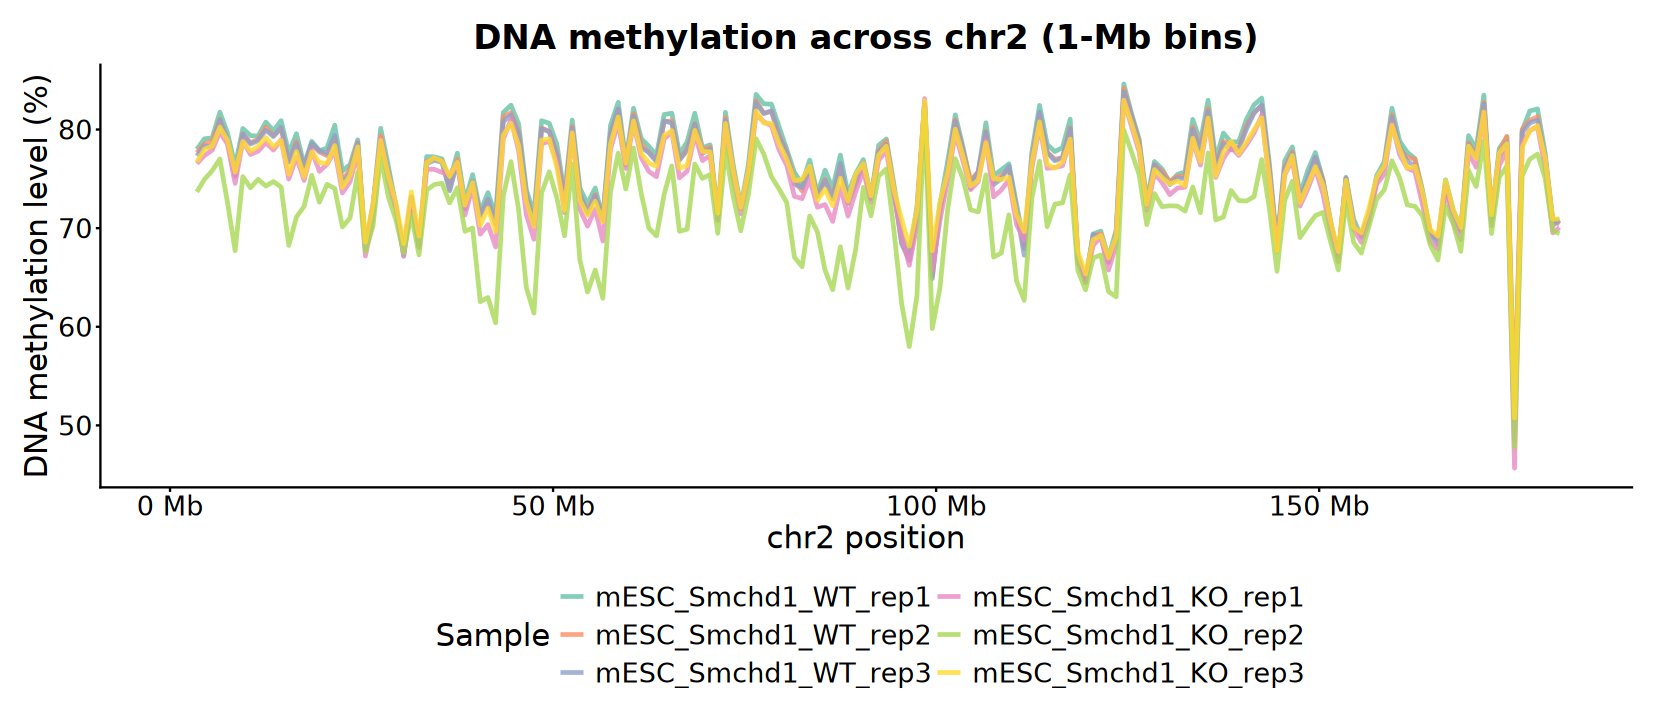

In [31]:
options(repr.plot.width = 14, repr.plot.height = 6)

do.call(c, bin_stats_list) |> 
    as.data.frame() |>
    mutate(position = (start + end) / 2) |>
    mutate(sample = factor(sample, levels = names(meth_list))) |>
ggplot(aes(x = position, y = meth, group = sample)) +
    geom_line(aes(color = sample), linewidth = 1, alpha = .8, na.rm = TRUE) +
    scale_x_continuous(
        limits = c(1, chrom_sizes), breaks = scales::breaks_width(5e7),
        labels = function(x) {paste0(x / 1e6, " Mb")}) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 3)) +
    labs(
        title = paste0("DNA methylation across ", chr_idx, " (1-Mb bins)"),
        x = paste0(chr_idx, " position"), 
        y = "DNA methylation level (%)",
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 2, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). Metagene Profile

In [32]:
GENES <- genes(txdb)
PROMOTERS <- promoters(GENES, upstream = 2000, downstream = 500)

  84 genes were dropped because they have exons located on both strands of the
  same reference sequence or on more than one reference sequence, so cannot be
  represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.



In [33]:
CGI <- read.table(
    "~/reference/Mus_musculus/mm9/ucsc/cpgIslandExt.txt",
    header = FALSE, sep = "\t", col.names = c(
        "bin", "chr", "start", "end", "names", "length",
        "cpgNum", "gcNum", "perCpg", "perGc", "obsExp")) |>
    dplyr::filter(length > 300) |>
    GRanges() |>
    keepStandardChromosomes(pruning.mode = "coarse")

In [34]:
PROMOTERS$CGI_status <- ifelse(
    overlapsAny(PROMOTERS, CGI), "CGI", "non_CGI") |> 
    factor(levels = c("CGI", "non_CGI"))
table(PROMOTERS$CGI_status)

CGI$Promoter_status <- ifelse(
    overlapsAny(CGI, PROMOTERS), "Promoter", "non_Promoter") |> 
    factor(levels = c("Promoter", "non_Promoter"))
table(CGI$Promoter_status)


    CGI non_CGI 
  10848   10829 


    Promoter non_Promoter 
        9759         3134 

### a). Genes

In [35]:
gene_mat_List <- lapply(
    meth_list, normalizeToMatrix, GENES, value_column = "meth",
    extend = 2000, mean_mode = "absolute", w = 50, 
    target_ratio = 0.4, background = NA, smooth = FALSE)

In [36]:
partition <- PROMOTERS$CGI_status

col_cluster <- c(CGI  = "#756BB1", non_CGI = "#BDBDBD")
col_meth <- circlize::colorRamp2(
    breaks = c(0, 50, 100),
    colors = c("#2166AC", "#F7F7F7", "#B2182B"))

lgd_cluster <- Legend(
    at = names(col_cluster), title = "CpG status",
    legend_gp = gpar(fill = col_cluster))
lgd_meth <- Legend(col_fun = col_meth, title = "DNAm (%)")

In [37]:
ht_list <- Heatmap(
    partition, name = "Genes", col = col_cluster, width = unit(3, "mm"),
    show_row_names = FALSE, show_heatmap_legend = FALSE)

for (idx in names(gene_mat_List)) {
    ht_list <- ht_list + EnrichedHeatmap(
        gene_mat_List[[idx]], name = idx, column_title = idx, 
        col = col_meth, show_heatmap_legend = FALSE, use_raster = TRUE,
        axis_name = c("-2kb", "TSS", "TES", "+2kb"),
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(col = col_cluster, lwd = 3),
                ylim = c(0, 100)),
            height = unit(4, "cm"),
            show_legend = FALSE))
}

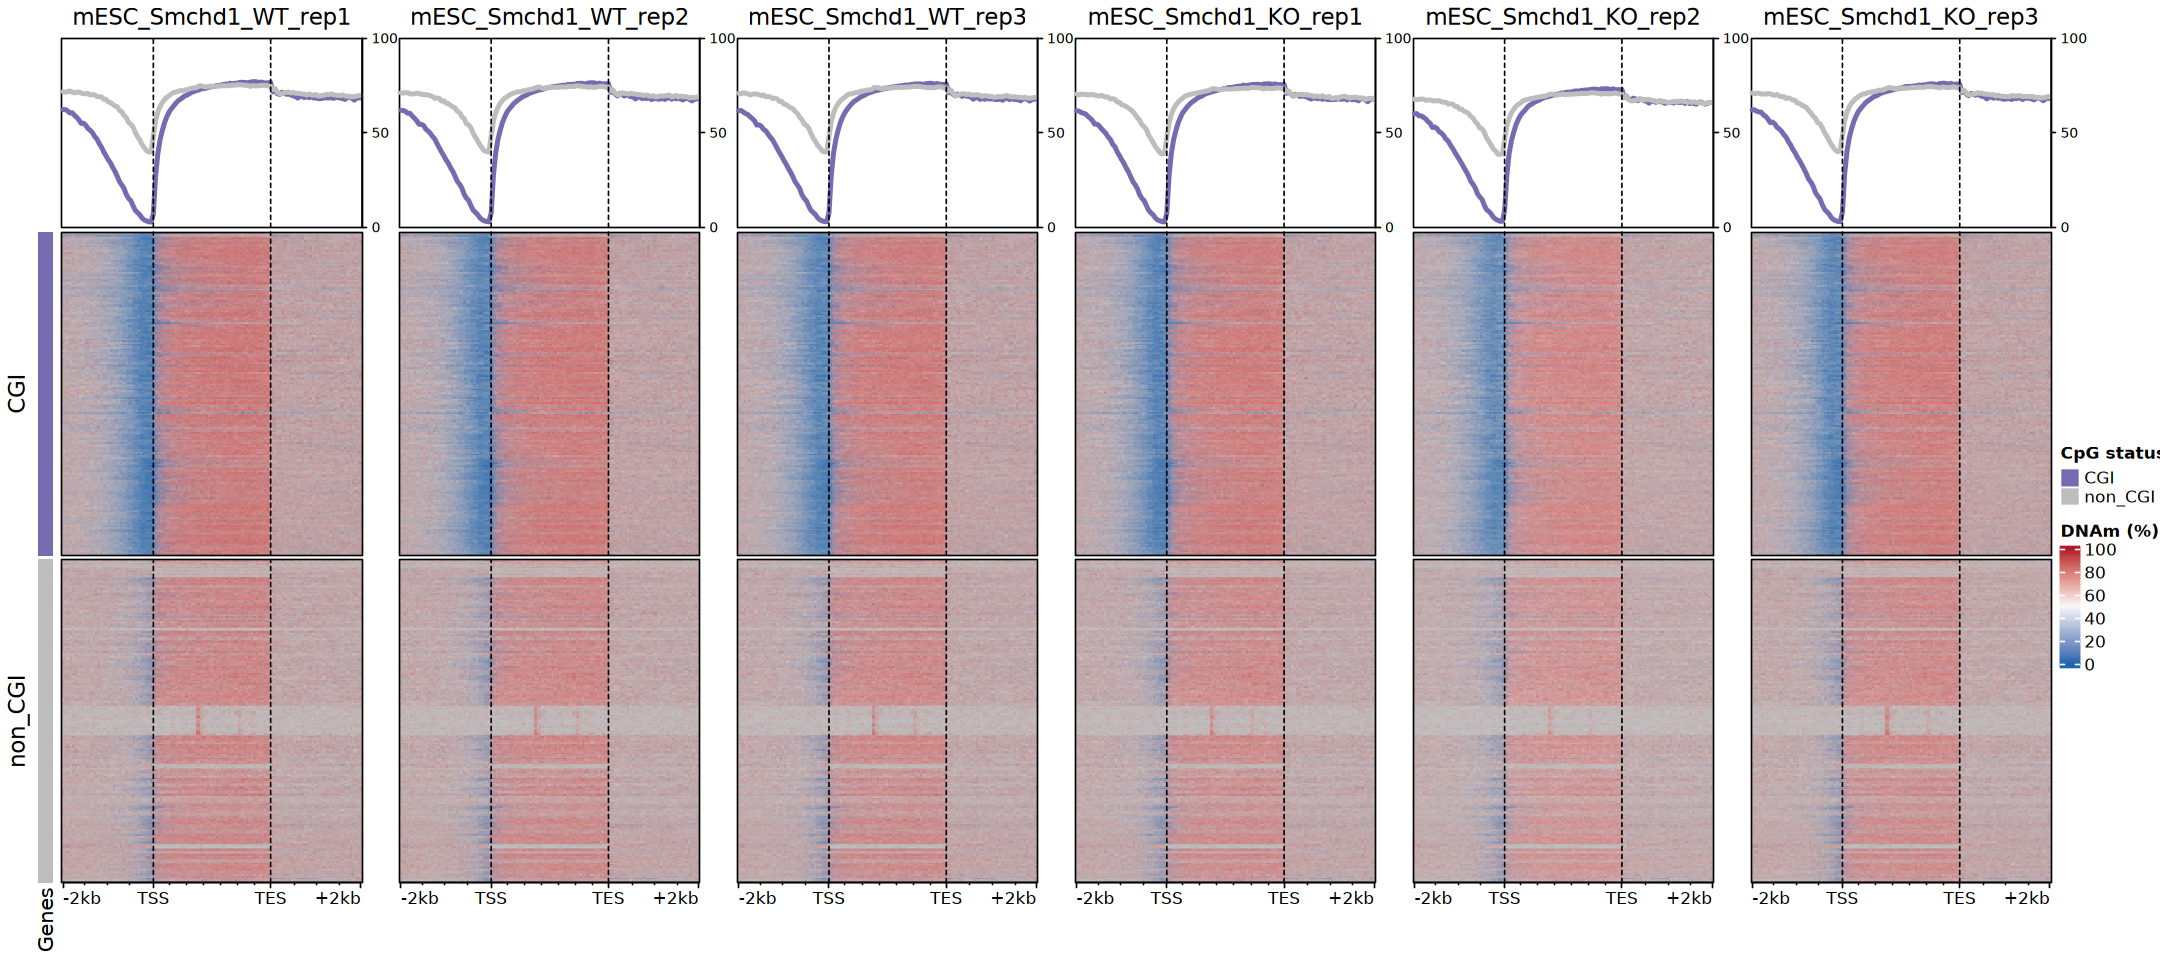

In [38]:
options(repr.plot.width = 18, repr.plot.height = 8)

draw(
    ht_list, split = partition, 
    annotation_legend_list = list(lgd_cluster, lgd_meth),
    ht_gap = unit(c(2, rep(8, length(gene_mat_List))), "mm"))

In [39]:
position_index <- c(
    paste0("u", seq_len(40)), 
    paste0("t", seq_len(53)), 
    paste0("d", seq_len(40))
)

plot_df <- gene_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "meth") |>
    mutate(pos = factor(pos, levels = position_index)) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = names(meth_list)))

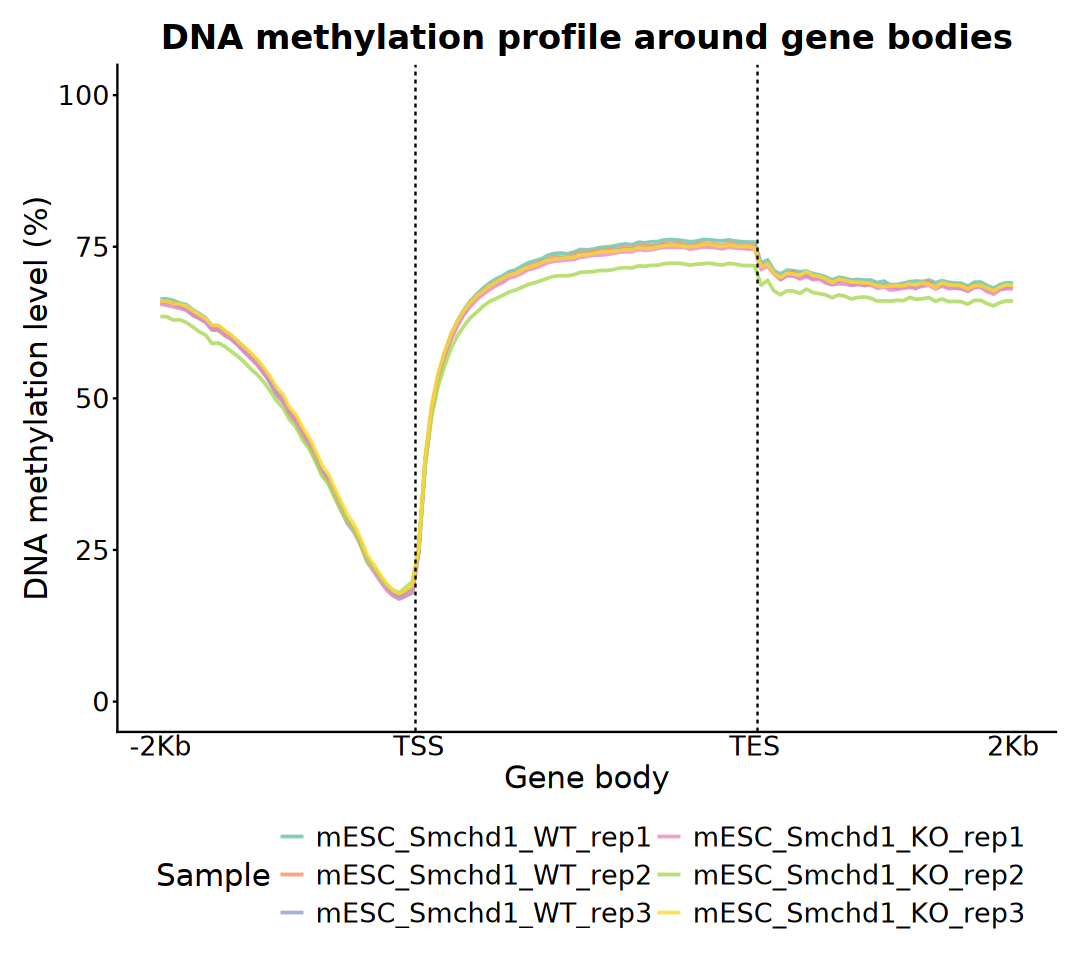

In [40]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = pos, y = meth, group = sample)) +
    geom_line(aes(color = sample), linewidth = .8, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = 40.5, linetype = 2) +
    geom_vline(xintercept = 93.5, linetype = 2) +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), expand = c(0.05, 0.05),
        labels = c("u1" = "-2Kb", "t1" = "TSS", "t53" = "TES", "d40" = "2Kb")) +
    coord_cartesian(ylim = c(0, 100)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 3)) +
    labs(
        title = "DNA methylation profile around gene bodies", 
        x = "Gene body", y = "DNA methylation level (%)", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16), 
        axis.ticks.x = element_blank())

### b). CGI

In [41]:
cgi_mat_List <- lapply(
    meth_list, normalizeToMatrix, CGI, value_column = "meth",
    extend = 4000, mean_mode = "absolute", w = 50, 
    target_ratio = 0.3, background = NA, smooth = FALSE)

In [42]:
partition <- CGI$Promoter_status

col_cluster <- c(Promoter  = "#1B9E77", non_Promoter = "#BDBDBD")
col_meth <- circlize::colorRamp2(
    breaks = c(0, 50, 100),
    colors = c("#2166AC", "#F7F7F7", "#B2182B"))

lgd_cluster <- Legend(
    at = names(col_cluster), title = "Promoter status",
    legend_gp = gpar(fill = col_cluster))
lgd_meth <- Legend(col_fun = col_meth, title = "DNAm (%)")

In [43]:
ht_list <- Heatmap(
    partition, name = "CGI", col = col_cluster, width = unit(3, "mm"),
    show_row_names = FALSE, show_heatmap_legend = FALSE)

for (idx in names(cgi_mat_List)) {
    ht_list <- ht_list + EnrichedHeatmap(
        cgi_mat_List[[idx]], name = idx, column_title = idx, 
        col = col_meth, show_heatmap_legend = FALSE, use_raster = TRUE,
        axis_name = c("-4kb", "start", "end", "+4kb"),
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(col = col_cluster, lwd = 3),
                ylim = c(0, 100)),
            height = unit(4, "cm"),
            show_legend = FALSE))
}

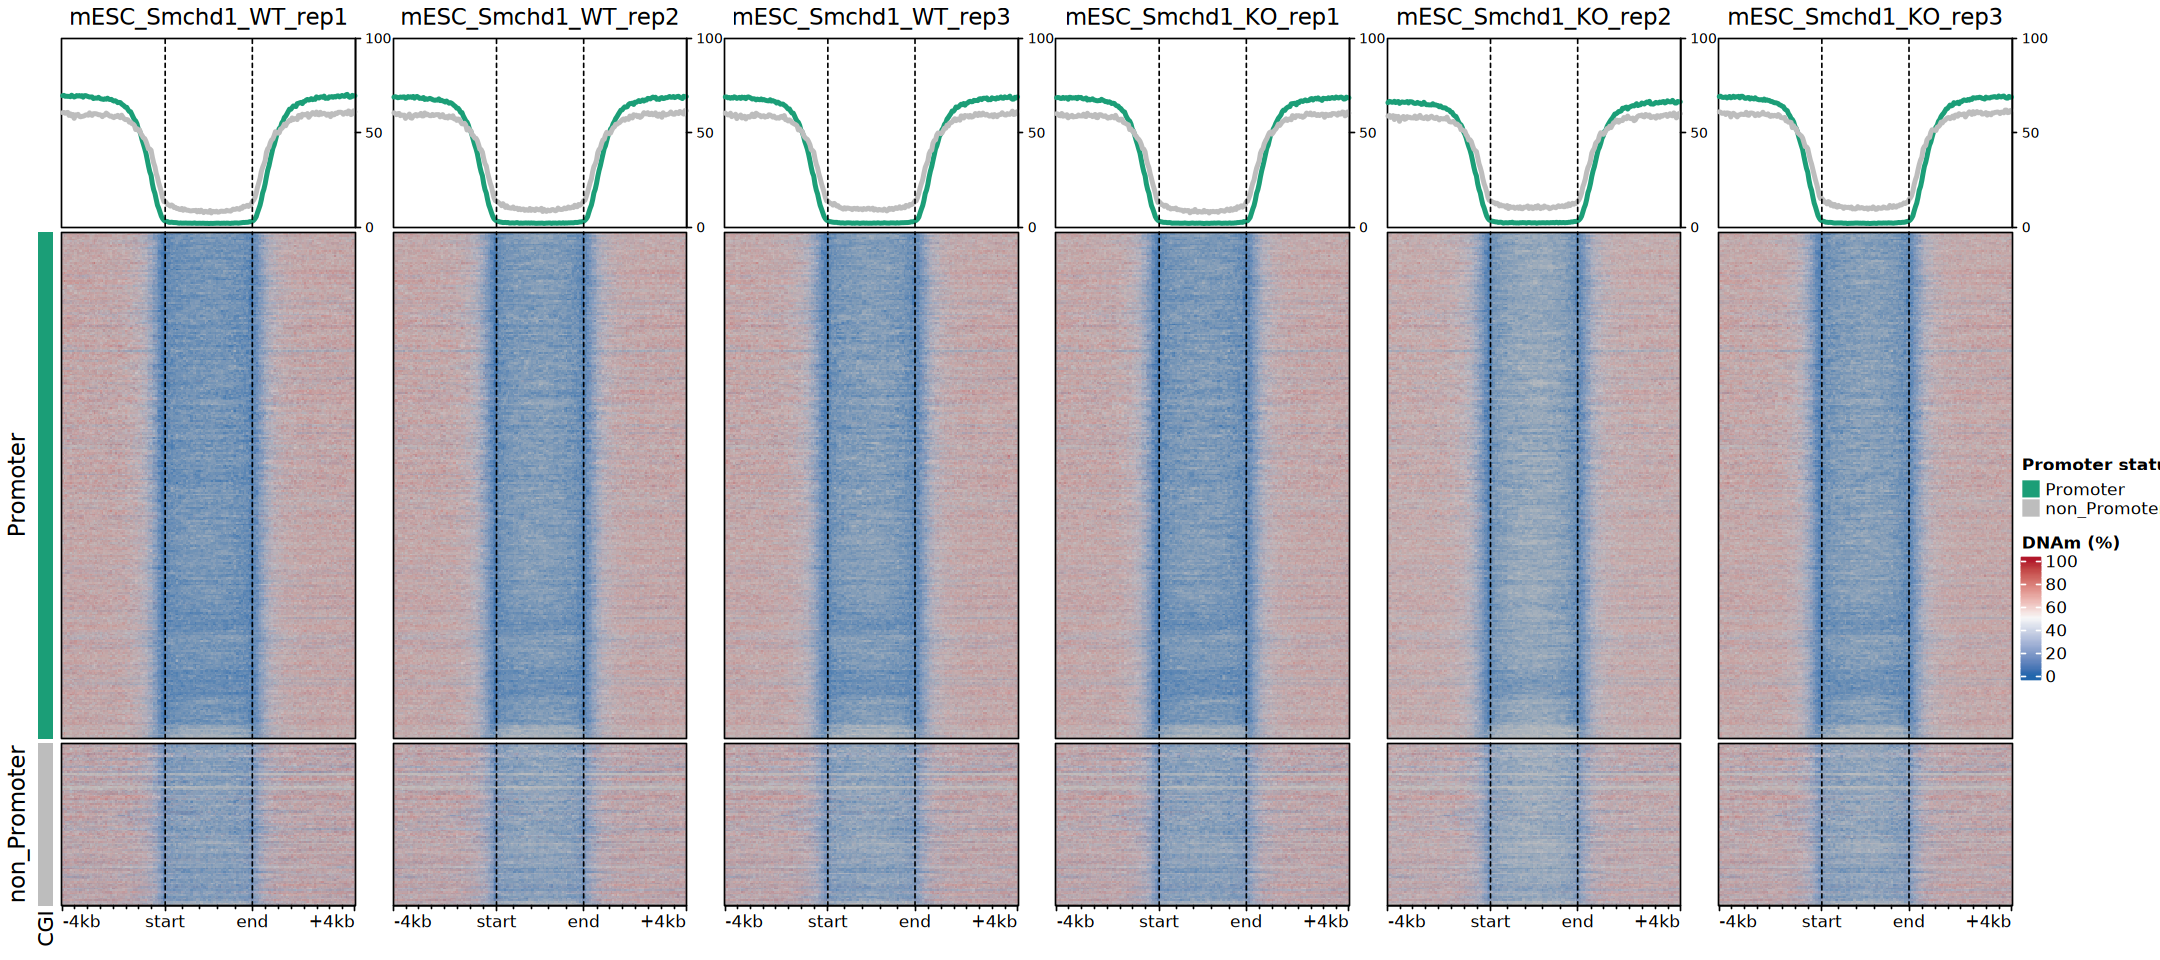

In [44]:
options(repr.plot.width = 18, repr.plot.height = 8)

draw(
    ht_list, split = partition, 
    annotation_legend_list = list(lgd_cluster, lgd_meth),
    ht_gap = unit(c(2, rep(8, length(cgi_mat_List))), "mm"))

In [45]:
position_index <- c(
    paste0("u", seq_len(80)), 
    paste0("t", seq_len(69)), 
    paste0("d", seq_len(80))
)

plot_df <- cgi_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "meth") |>
    mutate(pos = factor(pos, levels = position_index)) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = names(meth_list)))

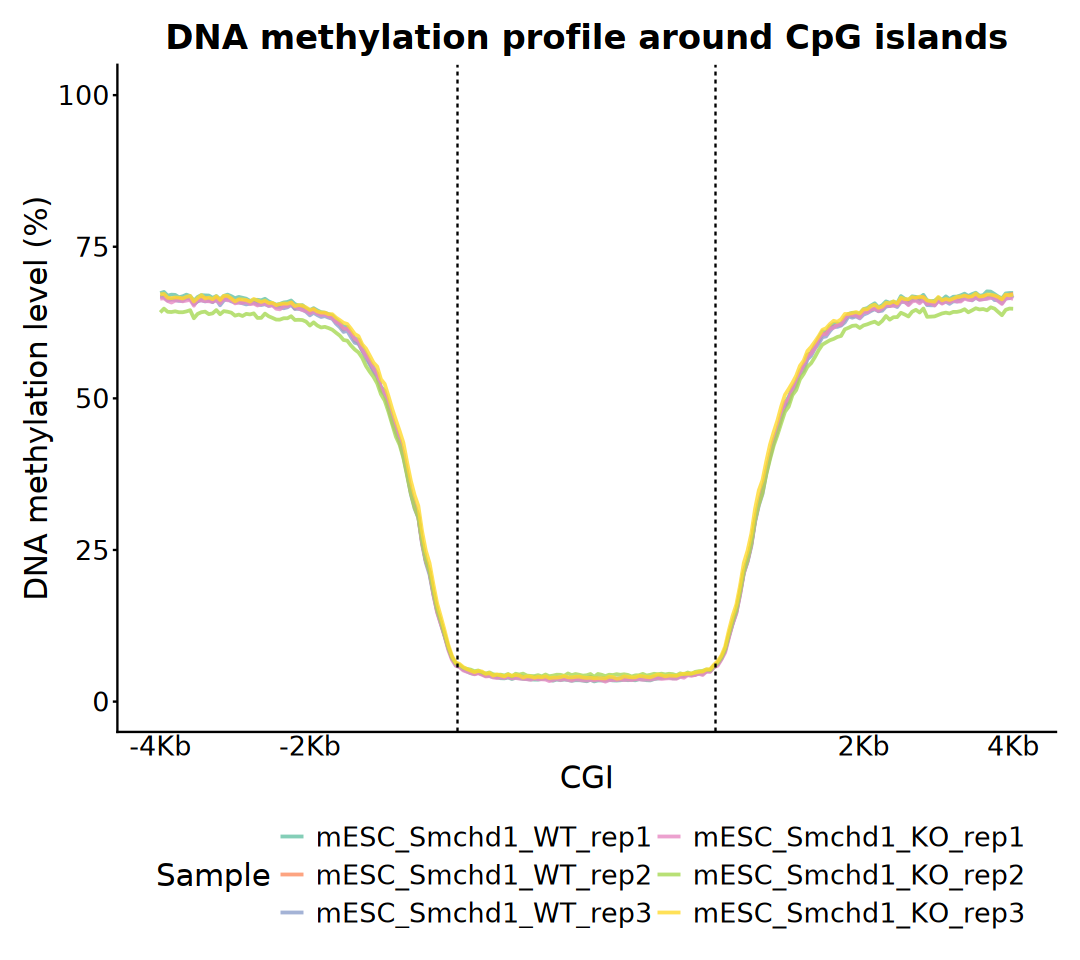

In [46]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = pos, y = meth, group = sample)) +
    geom_line(aes(color = sample), linewidth = .8, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = 80.5, linetype = 2) +
    geom_vline(xintercept = 149.5, linetype = 2) +
    scale_x_discrete(
        "CGI", expand = c(0.05, 0.05), 
        breaks = c("u1", "u41", "d40", "d80"), 
        labels = c(
            "u1" = "-4Kb", "u41" = "-2Kb", "d40" = "2Kb", "d80" = "4Kb")) +
    coord_cartesian(ylim = c(0, 100)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 3)) +
    labs(
        title = "DNA methylation profile around CpG islands",
        x = "CGI", y = "DNA methylation level (%)", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16), 
        axis.ticks.x = element_blank())

## 5). DNAm Distribution

In [47]:
gene <- genes(txdb)
promoter <- promoters(gene, upstream = 2000, downstream = 500)
downstream <- flank(gene, width = 2000, start = FALSE)

exon <- exonsBy(txdb, by = "gene")
intron <- intronsByTranscript(txdb)

utr5 <- fiveUTRsByTranscript(txdb)
cds <- cdsBy(txdb, by = "gene")
utr3 <- threeUTRsByTranscript(txdb)

gap <- c(gene, promoter, downstream) |> unstrand() |> gaps()
intergenic <- gap[strand(gap) == "*"]

  84 genes were dropped because they have exons located on both strands of the
  same reference sequence or on more than one reference sequence, so cannot be
  represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.

Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 3 out-of-bound ranges located on sequences chr12,
  chr13, and chr3. Note that ranges located on a sequence whose length is
  unknown (NA) or on a circular sequence are not considered out-of-bound (use
  seqlengths() and isCircular() to get the lengths and circularity flags of the
  underlying sequences). You can use trim() to trim these ranges. See
  ?`trim,GenomicRanges-method` for more information.”
Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 3 out-of-bound ranges located on sequences chr12,
  chr13, an

In [48]:
# CGI shore = ±2kb around CGI excluding CGI
# CGI shelf = 2–4kb around CGI excluding 0–2kb, CGI
cgi_2kb <- resize(CGI, width = width(CGI) + 4000, fix = "center")
cgi_shore <- setdiff(cgi_2kb, CGI)
cgi_4kb <- resize(CGI, width = width(CGI) + 8000, fix = "center")
cgi_shelf <- setdiff(cgi_4kb, cgi_2kb)

In [49]:
region_list <- list(
    CGI = CGI, CGI_Shore = cgi_shore, CGI_Shelf = cgi_shelf,
    Promoter = promoter, Exon = unlist(exon), Intron = unlist(intron),
    FiveUTR = unlist(utr5), CDS = unlist(cds), ThreeUTR = unlist(utr3),
    Downstream = downstream, Intergenic = intergenic
)

In [50]:
get_profile_data <- function(
    gr, region, region_id, bin = 50, method = c("mean", "ratio"), 
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    hits <- findOverlaps(gr, region, ignore.strand = TRUE)

    if(length(hits) == 0) return(NULL)

    gr_sub <- gr[queryHits(hits)]
    region_sub <- region[subjectHits(hits)]

    rel_pos <- (start(gr_sub) - start(region_sub)) / width(region_sub)
    is_minus <- as.character(strand(region_sub)) == "-"
    rel_pos[is_minus] <- 1 - rel_pos[is_minus]

    bin_idx <- ceiling(rel_pos * bin)
    bin_idx[bin_idx == 0] <- 1
    bin_idx[bin_idx > bin] <- bin

    if (method == "mean") {
        vals <- mcols(gr_sub)[[meth_col]]
        mean <- mean(vals, na.rm = TRUE)
        df <- tibble(bin = bin_idx, meth = vals) |> 
            group_by(bin) |>
            summarise(mean = mean(meth, na.rm = TRUE), .groups = "drop") |>
            mutate(region = region_id)
    } else if (method == "ratio") {
        numCs <- mcols(gr_sub)[[numCs_col]]
        numTs <- mcols(gr_sub)[[numTs_col]]
        df <- tibble(bin = bin_idx, numCs = numCs, numTs = numTs) |>
            group_by(bin) |>
            summarise(
                mean = sum(numCs) / sum(numCs + numTs) * 100, 
                .groups = "drop") |>
            mutate(region = region_id)
    }

    return(df)
}

In [51]:
region_index <- c(
    "Promoter", "FiveUTR", "Exon", "Intron", "ThreeUTR", 
    "Downstream", "Intergenic")

profiles_list <- list()

for (sample_idx in names(meth_list)) {
    meth <- meth_list[[sample_idx]]
    result <- lapply(region_index, function(idx) {
        region <- region_list[[idx]]
        df <- get_profile_data(
            meth, region, idx, bin = 50, method = "ratio")
        return(df)
    })

    profiles_list[[sample_idx]] <- bind_rows(result) |>
        mutate(
            sample = sample_idx, 
            region = factor(region, levels = region_index))
}

In [52]:
plot_df <- bind_rows(profiles_list) |>
    mutate(region_idx = as.numeric(region) - 1) |>
    mutate(global_idx = (region_idx * 50) + bin) |>
    mutate(sample = factor(sample, levels = names(meth_list)))

head(plot_df)

bin,mean,region,sample,region_idx,global_idx
<dbl>,<dbl>,<fct>,<fct>,<dbl>,<dbl>
1,67.17896,Promoter,mESC_Smchd1_WT_rep1,0,1
2,66.93151,Promoter,mESC_Smchd1_WT_rep1,0,2
3,66.67942,Promoter,mESC_Smchd1_WT_rep1,0,3
4,66.14390,Promoter,mESC_Smchd1_WT_rep1,0,4
5,66.16005,Promoter,mESC_Smchd1_WT_rep1,0,5
6,65.01158,Promoter,mESC_Smchd1_WT_rep1,0,6


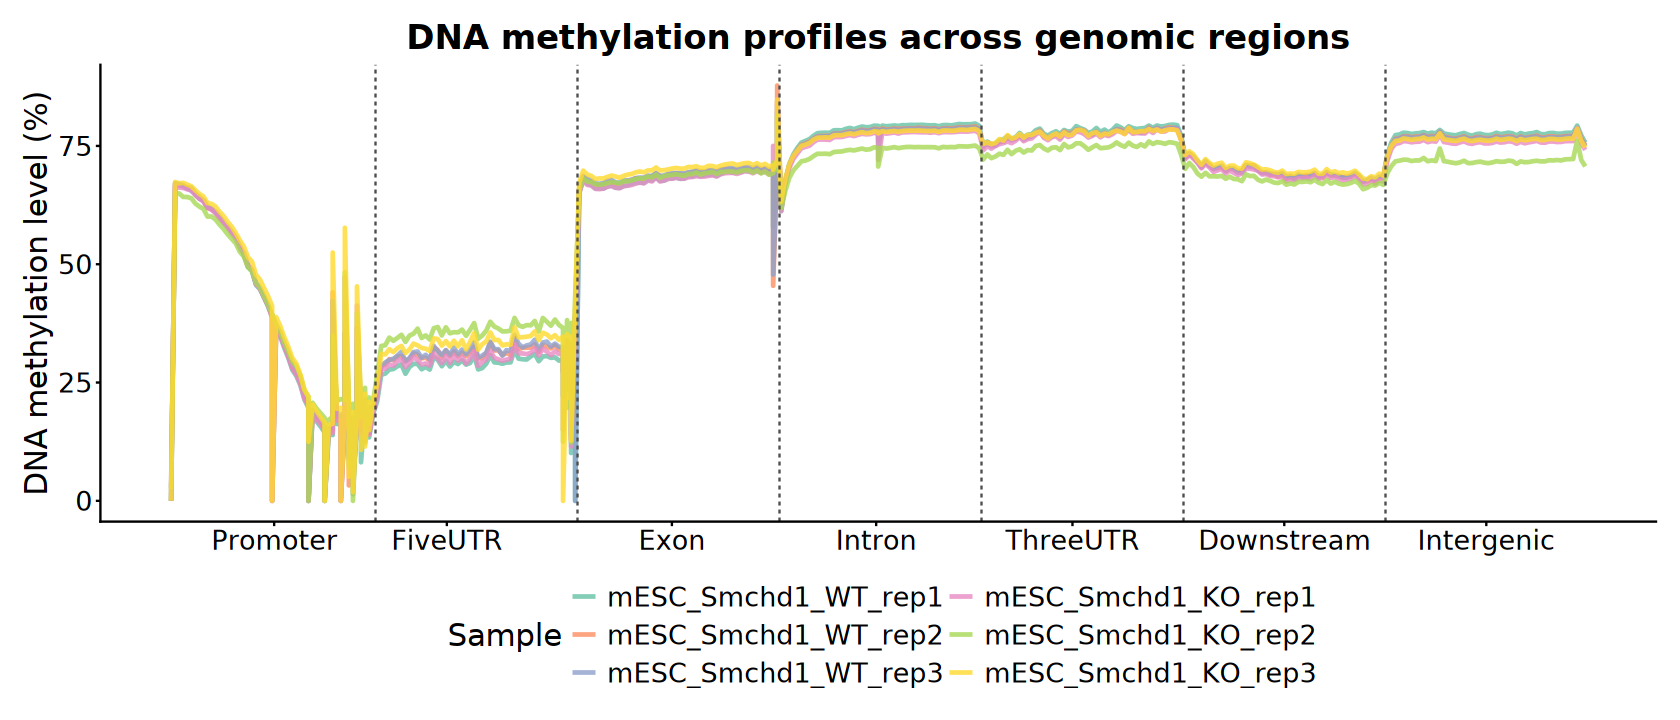

In [53]:
options(repr.plot.width = 14, repr.plot.height = 6)

x_labels_pos <- plot_df |> group_by(region) |>
    summarise(center_idx = mean(global_idx), .groups = "drop")
vlines_pos <- seq(50 + 0.5, max(plot_df$global_idx) - 50 + 0.5, by = 50)

ggplot(plot_df, aes(x = global_idx, y = mean, group = sample)) +
    geom_line(aes(color = sample), linewidth = 1, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = vlines_pos, color = "grey30", linetype = "dashed") +
    scale_x_continuous(
        breaks = x_labels_pos$center_idx, 
        labels = x_labels_pos$region) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 3)) +
    labs(
        title = "DNA methylation profiles across genomic regions",
        x = NULL, y = "DNA methylation level (%)", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [54]:
get_region_data <- function(
    gr, region_list, method = c("mean", "ratio"), 
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    map_dfr(names(region_list), function(idx) {
        hits <- findOverlaps(gr, region_list[[idx]], ignore.strand = TRUE)
        sub_gr <- gr[queryHits(hits)]

        if (method == "mean") {
            vals <- mcols(sub_gr)[[meth_col]]
            mean <- mean(vals, na.rm = TRUE)
        } else if (method == "ratio") {
            numCs <- mcols(sub_gr)[[numCs_col]]
            numTs <- mcols(sub_gr)[[numTs_col]]

            sumCs <- sum(numCs, na.rm = TRUE)
            sumTs <- sum(numTs, na.rm = TRUE)
            mean <- sumCs / (sumCs + sumTs) * 100
        }
        tibble(region = idx, numCpG = length(sub_gr), mean = mean)
    })
}

In [55]:
meth_df <- imap_dfr(meth_list, function(gr, sample_id) {
    get_region_data(gr = gr, region_list = region_list, method = "ratio")
}, .id = "sample") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(region = factor(region, levels = names(region_list)))

head(meth_df)

sample,region,numCpG,mean,Cell,Gene,Group,Replicate
<chr>,<fct>,<int>,<dbl>,<chr>,<chr>,<fct>,<fct>
mESC_Smchd1_WT_rep1,CGI,706623,4.171439,mESC,Smchd1,WT,rep1
mESC_Smchd1_WT_rep1,CGI_Shore,732866,41.265155,mESC,Smchd1,WT,rep1
mESC_Smchd1_WT_rep1,CGI_Shelf,474201,72.744346,mESC,Smchd1,WT,rep1
mESC_Smchd1_WT_rep1,Promoter,1166448,33.317826,mESC,Smchd1,WT,rep1
mESC_Smchd1_WT_rep1,Exon,1646946,68.074946,mESC,Smchd1,WT,rep1
mESC_Smchd1_WT_rep1,Intron,19289646,77.681257,mESC,Smchd1,WT,rep1


Ignoring unknown labels:
• shape : "Sample"


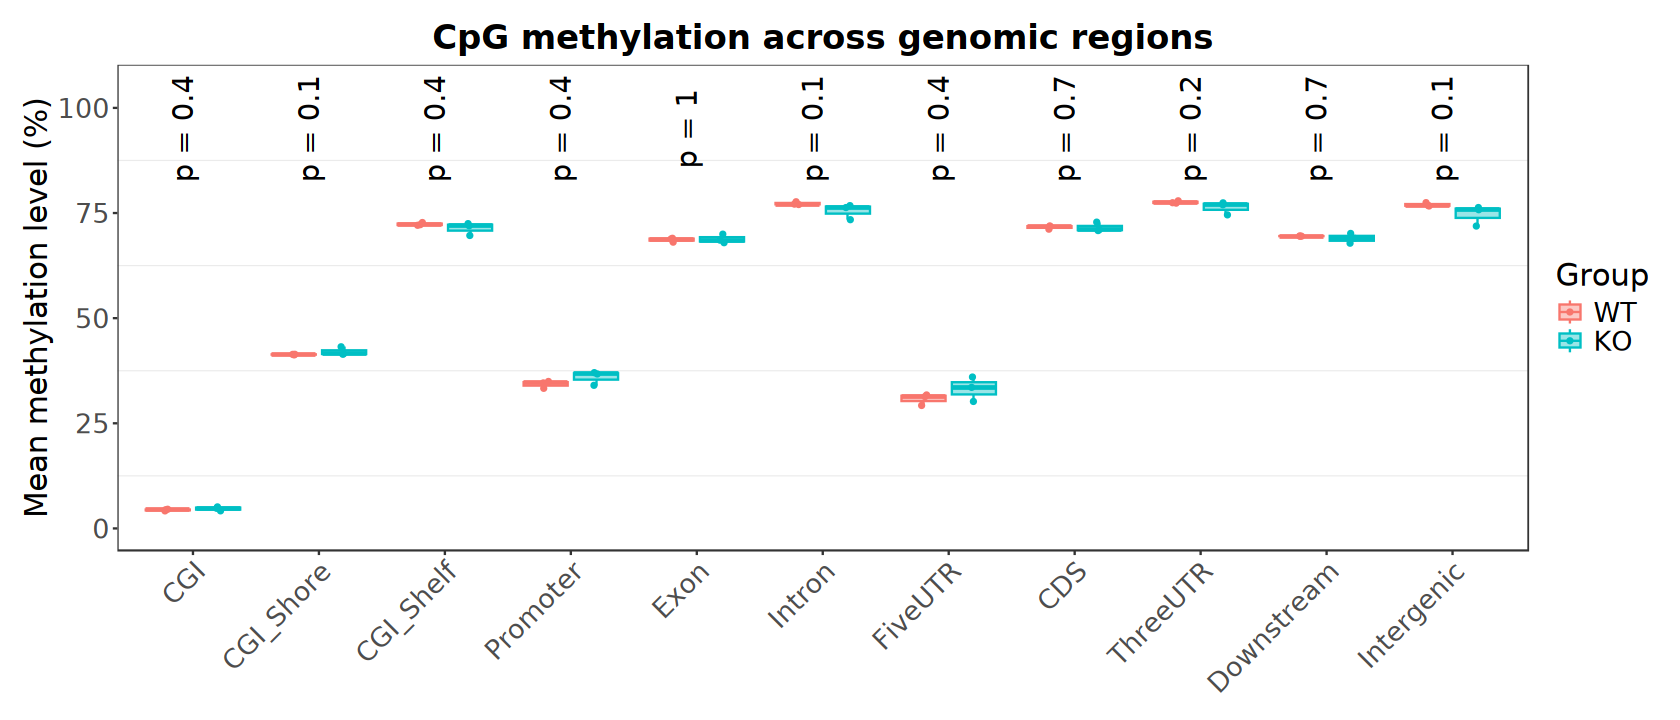

In [56]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(meth_df, aes(x = region, y = mean)) +
    geom_boxplot(
        aes(color = Group, fill = Group), 
        position = position_dodge(width = 0.8),
        width = 0.7, outlier.shape = NA, alpha = 0.4) +
    geom_point(
        aes(color = Group), size = 1, alpha = 1, 
        position = position_jitterdodge(
            jitter.width = 0.1, dodge.width = 0.8)) +
    stat_compare_means(
        aes(group = Group), method = "wilcox.test", label = "p.format", 
        size = 6, angle = 90, label.x.npc = "center", label.y = 95) +
    coord_cartesian(ylim = c(0, 105)) +
    labs(
        title = "CpG methylation across genomic regions", 
        x = NULL, y = "Mean methylation level (%)", 
        color = "Group", fill = "Group", shape = "Sample") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid.major = element_blank(),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

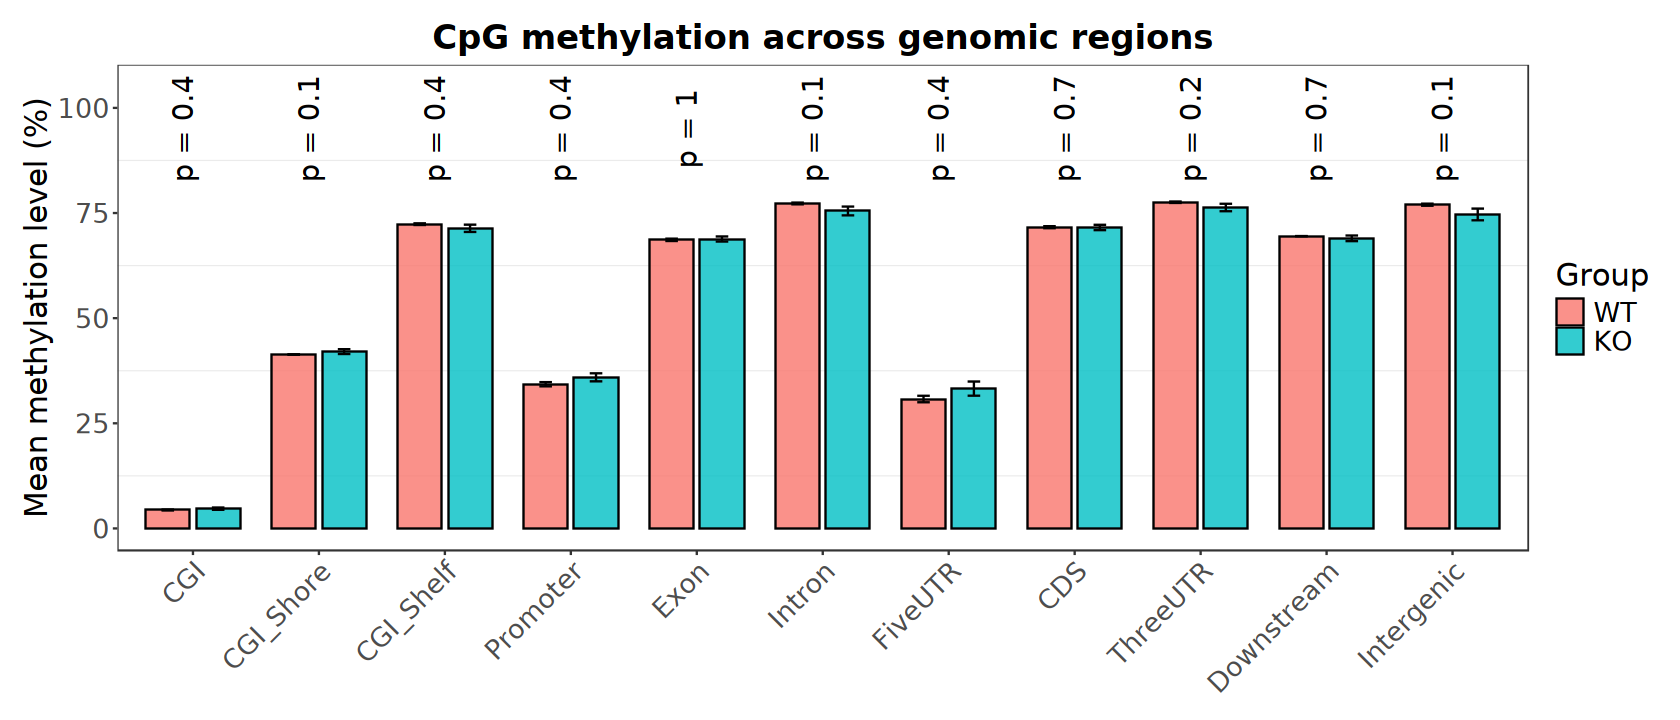

In [57]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(meth_df, aes(x = region, y = mean, color = Group, fill = Group)) +
    geom_bar(
        stat = "summary", fun = "mean", 
        position = position_dodge(width = 0.8), 
        color = "black", alpha = 0.8, width = 0.7) +
    stat_summary(
        fun.data = mean_se, geom = "errorbar", color = "black",
        position = position_dodge(width = 0.8), width = 0.2) +
    stat_compare_means(
        aes(group = Group), method = "wilcox.test", label = "p.format", 
        size = 6, angle = 90, label.x.npc = "center", label.y = 95) +
    labs(
        title = "CpG methylation across genomic regions", 
        x = NULL, y = "Mean methylation level (%)") +
    coord_cartesian(ylim = c(0, 105)) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid.major = element_blank(),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

# 5. DMRs

## [methylKit](https://www.bioconductor.org/packages/release/bioc/html/methylKit.html)

In [58]:
suppressPackageStartupMessages(library(methylKit))

### a). Preprocessing

In [59]:
meth_raw <- methRead(
    location = as.list(cov_files), 
    sample.id = as.list(names(cov_files)), 
    treatment = c(0, 0, 0, 1, 1, 1), 
    assembly = "mm9", mincov = 0, context = "CpG", 
    pipeline = "bismarkCoverage")

Received list of locations.

Uncompressing file.

Reading file.

Uncompressing file.

Reading file.

Uncompressing file.

Reading file.

Uncompressing file.

Reading file.

Uncompressing file.

Reading file.

Uncompressing file.

Reading file.



In [60]:
getSampleID(meth_raw)
getTreatment(meth_raw)
head(meth_raw[[1]])

[1] "mESC_Smchd1_WT_rep1" "mESC_Smchd1_WT_rep2" "mESC_Smchd1_WT_rep3"
[4] "mESC_Smchd1_KO_rep1" "mESC_Smchd1_KO_rep2" "mESC_Smchd1_KO_rep3"

[1] 0 0 0 1 1 1

,chr,start,end,strand,coverage,numCs,numTs
,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>
1,chr2,3000165,3000165,*,12,6,6
2,chr2,3000215,3000215,*,8,7,1
3,chr2,3000216,3000216,*,15,14,1
4,chr2,3000222,3000222,*,8,5,3
5,chr2,3000223,3000223,*,15,11,4
6,chr2,3000397,3000397,*,9,9,0


In [61]:
add_inferred_strand <- function(meth, genome) {
    infer_strand <- function(df) {
        base <- getSeq(genome, GRanges(df), as.character = TRUE)
        strand <- c(C = "+", G = "-", other = "*")
        unname(ifelse(
            base == "C", strand["C"], ifelse(
                base == "G", strand["G"], strand["other"])))
    }

    # case 1: methylRawList
    if (inherits(meth, "methylRawList")) {
        meth <- lapply(meth, function(x) {
            x$strand <- infer_strand(getData(x))
            return(x)
        }) |> 
            methylRawList(treatment = getTreatment(meth))
        return(meth)
    }

    # case 2: methylRaw / methylBase
    if (inherits(meth, "methylRaw") || inherits(meth, "methylBase")) {
        meth$strand <- infer_strand(getData(meth))
        return(meth)
    }

    stop("Unsupported methylKit object: ", paste(class(meth), collapse = ", "))
}

In [62]:
# ~ 6 min
meth_modify <- add_inferred_strand(meth_raw, genome)

In [63]:
head(meth_modify[[1]])

,chr,start,end,strand,coverage,numCs,numTs
,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>
1,chr2,3000165,3000165,-,12,6,6
2,chr2,3000215,3000215,+,8,7,1
3,chr2,3000216,3000216,-,15,14,1
4,chr2,3000222,3000222,+,8,5,3
5,chr2,3000223,3000223,-,15,11,4
6,chr2,3000397,3000397,+,9,9,0


In [64]:
meth_filter <- filterByCoverage(meth_modify, lo.count = 5, hi.perc = 99.9)

In [65]:
# ~ 6 min
meth_unite <- unite(meth_filter, destrand = TRUE)

destranding...



uniting...



In [66]:
getSampleID(meth_unite)
getTreatment(meth_unite)
getData(meth_unite) |> head()

[1] "mESC_Smchd1_WT_rep1" "mESC_Smchd1_WT_rep2" "mESC_Smchd1_WT_rep3"
[4] "mESC_Smchd1_KO_rep1" "mESC_Smchd1_KO_rep2" "mESC_Smchd1_KO_rep3"

[1] 0 0 0 1 1 1

,chr,start,end,strand,coverage1,numCs1,numTs1,coverage2,numCs2,numTs2,⋯,numTs3,coverage4,numCs4,numTs4,coverage5,numCs5,numTs5,coverage6,numCs6,numTs6
,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,chr1,3000574,3000574,+,23,20,3,25,19,6,⋯,5,28,26,2,30,26,4,30,23,7
2,chr1,3000726,3000726,+,5,3,2,5,3,2,⋯,4,19,9,10,17,7,10,16,7,9
3,chr1,3001346,3001346,+,15,12,3,6,5,1,⋯,1,8,7,1,13,10,3,11,11,0
4,chr1,3001394,3001394,+,16,14,2,7,6,1,⋯,1,7,6,1,16,12,4,10,10,0
5,chr1,3001631,3001631,+,49,44,5,42,36,6,⋯,8,45,36,9,51,40,11,38,33,5
6,chr1,3002177,3002177,+,32,29,3,36,35,1,⋯,3,30,29,1,36,30,6,36,29,7


In [67]:
# getCorrelation(meth_unite, method = "spearman", plot = FALSE)

In [68]:
corr_mat <- percMethylation(meth_unite) |>
    cor(method = "spearman", use = "complete.obs")

dimnames(corr_mat) <- lapply(
    dimnames(corr_mat), \(x) sub("^mESC_Smchd1_", "", x))

corr_mat

,WT_rep1,WT_rep2,WT_rep3,KO_rep1,KO_rep2,KO_rep3
WT_rep1,1.0000000,0.7005822,0.6986703,0.6970085,0.7023877,0.6911418
WT_rep2,0.7005822,1.0000000,0.6933011,0.6917777,0.6973076,0.6868288
WT_rep3,0.6986703,0.6933011,1.0000000,0.6897089,0.6944030,0.6843987
KO_rep1,0.6970085,0.6917777,0.6897089,1.0000000,0.7015148,0.6873749
KO_rep2,0.7023877,0.6973076,0.6944030,0.7015148,1.0000000,0.6968423
KO_rep3,0.6911418,0.6868288,0.6843987,0.6873749,0.6968423,1.0000000


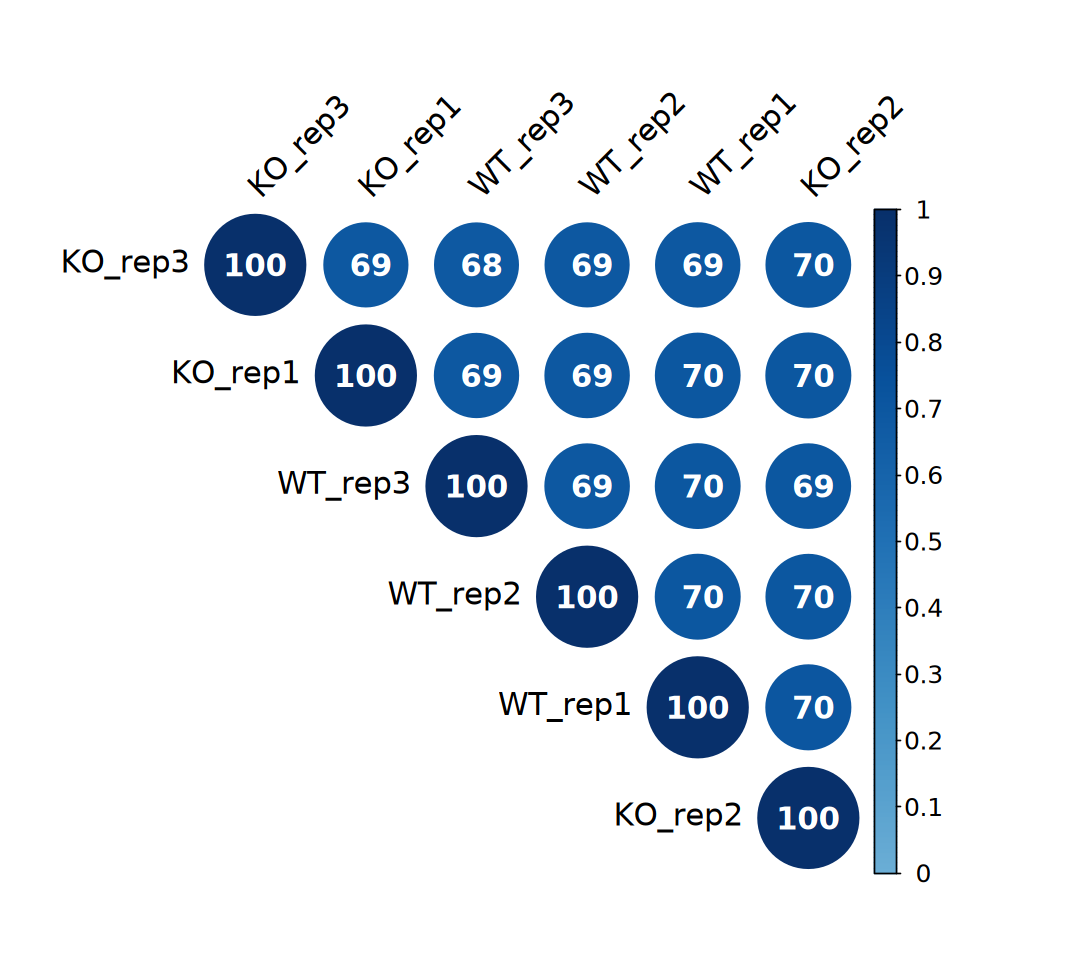

In [69]:
options(repr.plot.width = 9, repr.plot.height = 8)

corrplot::corrplot(
    corr_mat, method = "circle", type = "upper", order = "hclust", 
    col.lim = c(0, 1), col = colorRampPalette(brewer.pal(9, "Blues"))(255), 
    addgrid.col = NA, addCoef.col = "white", addCoefasPercent = TRUE,
    tl.cex = 1.5, tl.col = "black", tl.srt = 45, 
    cl.cex = 1.2, number.cex = 1.5)

### b). Tiling Windows

In [70]:
# ~ 2 min
meth_tiles <- tileMethylCounts(
    meth_unite, win.size = 1000, step.size = 500, cov.bases = 10)

In [71]:
getData(meth_tiles) |> head()

,chr,start,end,strand,coverage1,numCs1,numTs1,coverage2,numCs2,numTs2,⋯,numTs3,coverage4,numCs4,numTs4,coverage5,numCs5,numTs5,coverage6,numCs6,numTs6
,<fct>,<int>,<int>,<fct>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,chr1,3035001,3036000,*,226,194,32,234,210,24,⋯,19,216,172,44,281,221,60,216,193,23
2,chr1,3043501,3044500,*,201,148,53,161,123,38,⋯,45,126,94,32,155,104,51,214,159,55
3,chr1,3044001,3045000,*,164,139,25,159,133,26,⋯,22,138,123,15,138,121,17,119,102,17
4,chr1,3044501,3045500,*,311,265,46,334,285,49,⋯,60,329,271,58,338,289,49,336,295,41
5,chr1,3048501,3049500,*,356,291,65,343,249,94,⋯,60,299,231,68,432,336,96,376,299,77
6,chr1,3049001,3050000,*,414,348,66,383,301,82,⋯,62,303,234,69,495,397,98,412,340,72


In [72]:
# ~ 15 min
methylkit_dmrs <- calculateDiffMeth(
    meth_tiles, overdispersion = "MN", mc.cores = 1)

head(methylkit_dmrs)

two groups detected:
 will calculate methylation difference as the difference of
treatment (group: 1) - control (group: 0)



,chr,start,end,strand,pvalue,qvalue,meth.diff
,<fct>,<int>,<int>,<fct>,<dbl>,<dbl>,<dbl>
1,chr1,3035001,3036000,*,0.16045882,0.5968848,-5.9637205
2,chr1,3043501,3044500,*,0.25484004,0.6487056,-3.1064746
3,chr1,3044001,3045000,*,0.07429882,0.5222752,4.3765459
4,chr1,3044501,3045500,*,0.58555828,0.8007509,1.1743803
5,chr1,3048501,3049500,*,0.89170325,0.9143513,-0.4463057
6,chr1,3049001,3050000,*,0.68475661,0.8408037,-0.9517080


In [73]:
# Get hyper/hypo methylated DMRs
hyper_dmrs <- getMethylDiff(
    methylkit_dmrs, difference = 10, qvalue = 0.01, type = "hyper")
hypo_dmrs <- getMethylDiff(
    methylkit_dmrs, difference = 10, qvalue = 0.01, type = "hypo")
# Get all differentially methylated DMRs
diff_dmrs <- getMethylDiff(methylkit_dmrs, difference = 10, qvalue = 0.01)

In [74]:
message(
    "DMRs summary (methylKit):\n",
    "--------------------------------\n",
    "Hyper-methylated DMRs: ", nrow(hyper_dmrs), "\n",
    "Hypo-methylated DMRs : ", nrow(hypo_dmrs), "\n",
    "Total DMRs           : ", nrow(diff_dmrs), "\n",
    "--------------------------------"
)

DMRs summary (methylKit):
--------------------------------
Hyper-methylated DMRs: 251
Hypo-methylated DMRs : 308
Total DMRs           : 559
--------------------------------



### c). Predefined Regions

In [75]:
# GENES <- genes(txdb)
PROMOTERS <- promoters(GENES, upstream = 2000, downstream = 500)

In [76]:
meth_regions <- regionCounts(meth_unite, PROMOTERS)

getData(meth_regions) |> head()

,chr,start,end,strand,coverage1,numCs1,numTs1,coverage2,numCs2,numTs2,⋯,numTs3,coverage4,numCs4,numTs4,coverage5,numCs5,numTs5,coverage6,numCs6,numTs6
,<fct>,<int>,<int>,<fct>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,chr1,3661080,3663579,-,505,82,423,399,99,300,⋯,273,438,80,358,360,88,272,371,75,296
2,chr1,4398823,4401322,-,435,304,131,457,325,132,⋯,126,472,319,153,478,311,167,458,309,149
3,chr1,4485995,4488494,-,1230,167,1063,1122,191,931,⋯,1025,1037,149,888,925,152,773,1128,215,913
4,chr1,4775308,4777807,-,925,153,772,906,163,743,⋯,654,884,173,711,798,148,650,934,184,750
5,chr1,4795974,4798473,+,821,254,567,794,217,577,⋯,493,716,218,498,786,241,545,826,287,539
6,chr1,4845775,4848274,+,892,212,680,674,165,509,⋯,559,774,132,642,793,125,668,873,183,690


In [77]:
methylkit_regions <- calculateDiffMeth(
    meth_regions, overdispersion = "MN", mc.cores = 1)

head(methylkit_regions)

two groups detected:
 will calculate methylation difference as the difference of
treatment (group: 1) - control (group: 0)



,chr,start,end,strand,pvalue,qvalue,meth.diff
,<fct>,<int>,<int>,<fct>,<dbl>,<dbl>,<dbl>
1,chr1,3661080,3663579,-,0.74651640,0.8916051,1.109578
2,chr1,4398823,4401322,-,0.04688818,0.5125660,-3.546843
3,chr1,4485995,4488494,-,0.29124569,0.7221447,2.320130
4,chr1,4775308,4777807,-,0.18190828,0.6590579,1.432263
5,chr1,4795974,4798473,+,0.68394356,0.8745501,1.116403
6,chr1,4845775,4848274,+,0.07565743,0.5620309,-4.894903


In [78]:
# Get hyper/hypo methylated DMRs
hyper_regions <- getMethylDiff(
    methylkit_regions, difference = 10, qvalue = 0.01, type = "hyper")
hypo_regions <- getMethylDiff(
    methylkit_regions, difference = 10, qvalue = 0.01, type = "hypo")
diff_regions <- getMethylDiff(
    methylkit_regions, difference = 10, qvalue = 0.01)

In [79]:
message(
    "Promoters summary (methylKit):\n",
    "--------------------------------\n",
    "Hyper-methylated promoters: ", nrow(hyper_regions), "\n",
    "Hypo-methylated promoters : ", nrow(hypo_regions), "\n",
    "Total promoters           : ", nrow(diff_regions), "\n",
    "--------------------------------"
)

Promoters summary (methylKit):
--------------------------------
Hyper-methylated promoters: 5
Hypo-methylated promoters : 5
Total promoters           : 10
--------------------------------



# 6. DMRs Annotation

In [80]:
suppressPackageStartupMessages(library(ChIPseeker))
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [81]:
diff_dmrs_df <- diff_dmrs |> getData() |> as.data.frame() |>
    mutate(
        result = case_when(
            meth.diff > 0 ~ "Hyper", meth.diff < 0 ~ "Hypo", TRUE ~ "NS") |> 
        factor(levels = c("Hyper", "Hypo", "NS"))) |>
    as("GRanges")

diff_dmrs_df

GRanges object with 559 ranges and 4 metadata columns:
          seqnames            ranges strand |      pvalue      qvalue meth.diff
             <Rle>         <IRanges>  <Rle> |   <numeric>   <numeric> <numeric>
      498     chr1   5666501-5667500      * | 3.49601e-10 2.85706e-06  -14.6336
     8390     chr1 36018501-36019500      * | 1.13792e-07 2.27998e-04  -10.3003
    15386     chr1 51346001-51347000      * | 6.87195e-09 3.08115e-05  -10.3835
    19298     chr1 59451001-59452000      * | 3.83197e-05 9.80371e-03  -11.6186
    22339     chr1 66746001-66747000      * | 1.17791e-06 1.15418e-03  -10.6628
      ...      ...               ...    ... .         ...         ...       ...
  1215821     chrY   1295501-1296500      * | 3.60030e-07 5.25143e-04   15.9823
  1215863     chrY   2617001-2618000      * | 2.35727e-06 1.78663e-03   14.2682
  1215877     chrY   2657501-2658500      * | 4.57666e-06 2.68398e-03   13.8318
  1215878     chrY   2658001-2659000      * | 8.02052e-08 1.85584

In [82]:
diff_dmrs_df <- annotatePeak(
    diff_dmrs_df, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "gene", verbose = FALSE,
    genomicAnnotationPriority = c(
        "Promoter", "Exon", "Intron", "Intergenic"))

>> Using Genome: mm9 ...
>> Using Genome: mm9 ...
>> Using Genome: mm9 ...


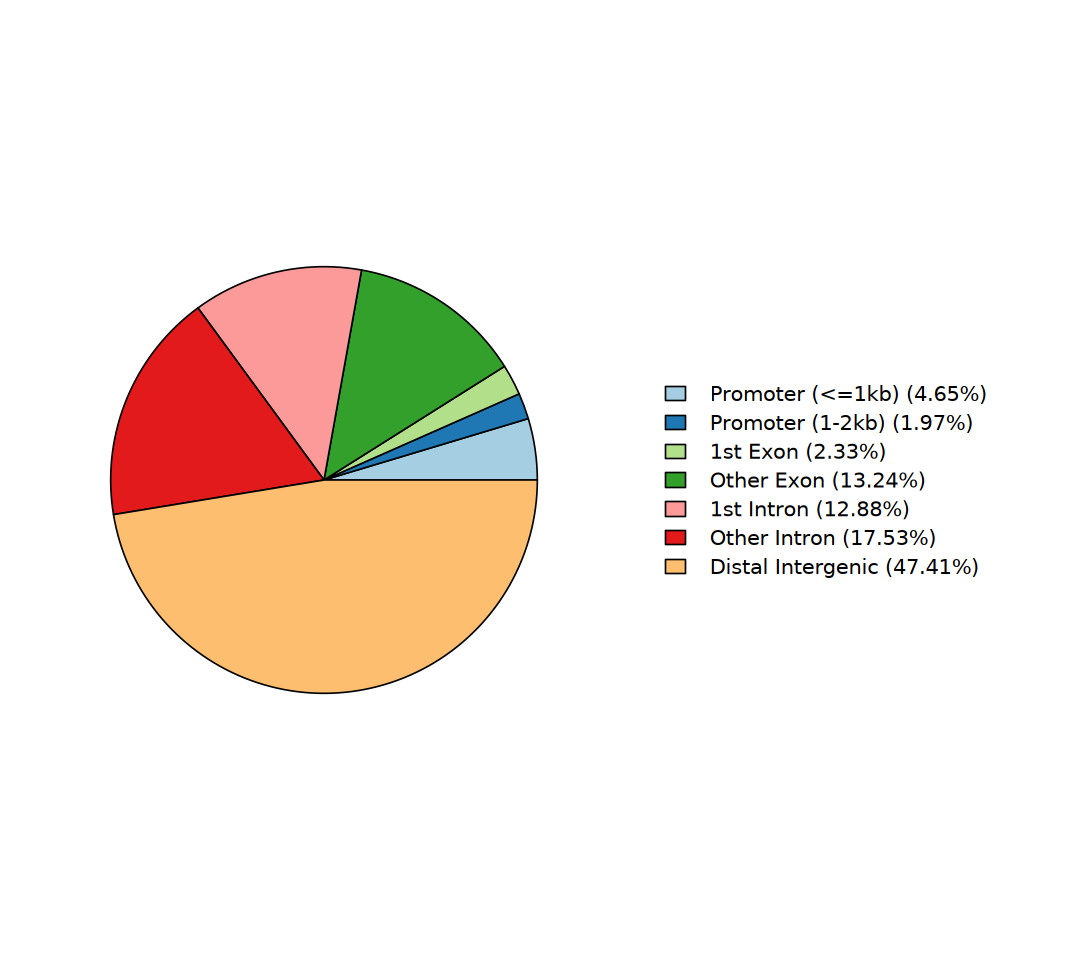

In [83]:
options(repr.plot.width = 9, repr.plot.height = 8)

plotAnnoPie(diff_dmrs_df, cex = 1)

In [84]:
diff_dmrs_anno <- diff_dmrs_df@anno

head(diff_dmrs_anno)

GRanges object with 6 ranges and 12 metadata columns:
        seqnames            ranges strand |      pvalue      qvalue meth.diff
           <Rle>         <IRanges>  <Rle> |   <numeric>   <numeric> <numeric>
    498     chr1   5666501-5667500      * | 3.49601e-10 2.85706e-06  -14.6336
   8390     chr1 36018501-36019500      * | 1.13792e-07 2.27998e-04  -10.3003
  15386     chr1 51346001-51347000      * | 6.87195e-09 3.08115e-05  -10.3835
  19298     chr1 59451001-59452000      * | 3.83197e-05 9.80371e-03  -11.6186
  22339     chr1 66746001-66747000      * | 1.17791e-06 1.15418e-03  -10.6628
  24090     chr1 72277001-72278000      * | 1.76697e-10 1.68271e-06  -15.0591
          result        annotation   geneChr geneStart   geneEnd geneLength
        <factor>       <character> <integer> <integer> <integer>  <integer>
    498     Hypo Distal Intergenic         1   5578574   5592947      14374
   8390     Hypo Distal Intergenic         1  36125245  36163291      38047
  15386     Hypo  

In [85]:
gene_map <- bitr(
    diff_dmrs_anno$geneId, OrgDb = org.Mm.eg.db, drop = FALSE, 
    fromType = "ENTREZID", toType = "SYMBOL")

head(gene_map)

'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(diff_dmrs_anno$geneId, OrgDb = org.Mm.eg.db, drop = FALSE, :
“1.04% of input gene IDs are fail to map...”


,ENTREZID,SYMBOL
,<chr>,<chr>
1,18387,Oprk1
2,50785,Hs6st1
3,20324,Cavin2
4,14369,Fzd7
5,66646,Rpe
6,381269,Mreg


In [86]:
mcols(diff_dmrs_anno)$geneSymbol <- gene_map$SYMBOL[
    match(diff_dmrs_anno$geneId, gene_map$ENTREZID)
]

In [87]:
gene_list <- diff_dmrs_anno |> mcols() |> as.data.frame() |>
    dplyr::filter(!is.na(geneId), geneId != "") |>
    dplyr::select(result, geneId, geneSymbol) |>
    distinct(result, geneId, geneSymbol)

gene_entrez <- split(gene_list$geneId, gene_list$result)

In [88]:
ego_compare <- compareCluster(
    geneCluster = gene_entrez, fun = enrichGO, 
    universe = unique(GENES$gene_id), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'ENTREZID', pAdjustMethod = "BH", 
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

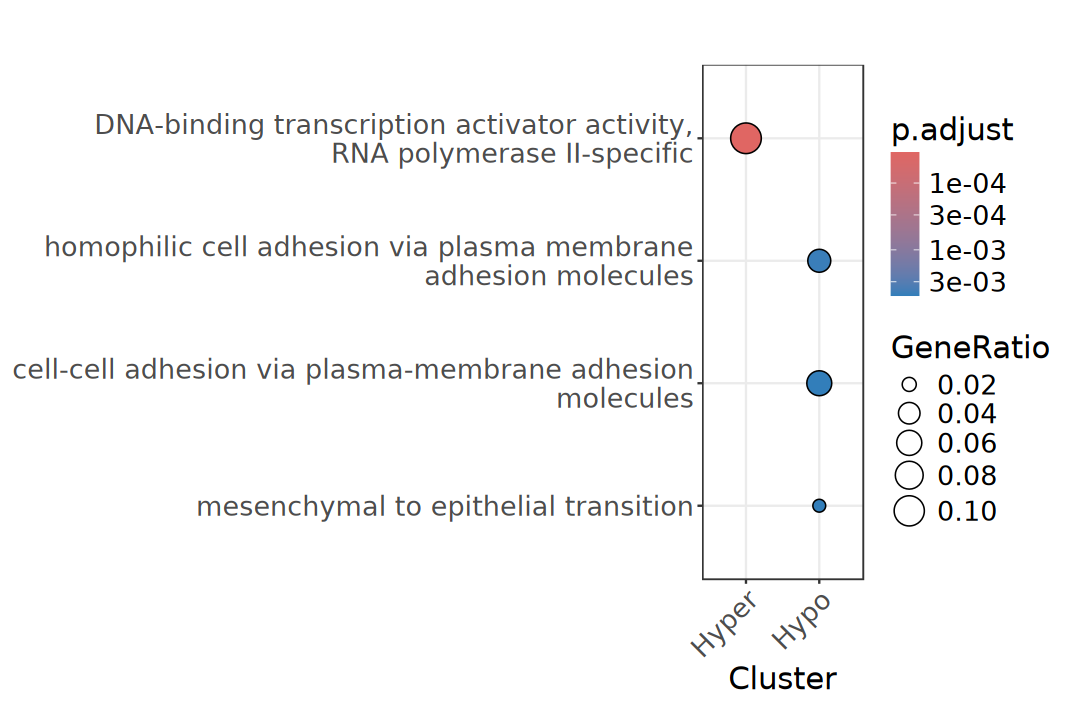

In [89]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 16))

In [90]:
ekegg_compare <- compareCluster(
    geneCluster = gene_entrez, fun = enrichKEGG, 
    universe = unique(GENES$gene_id), 
    organism = "mmu", pAdjustMethod = "BH", 
    pvalueCutoff = 1, qvalueCutoff = 1, 
    minGSSize = 10, maxGSSize = 500)

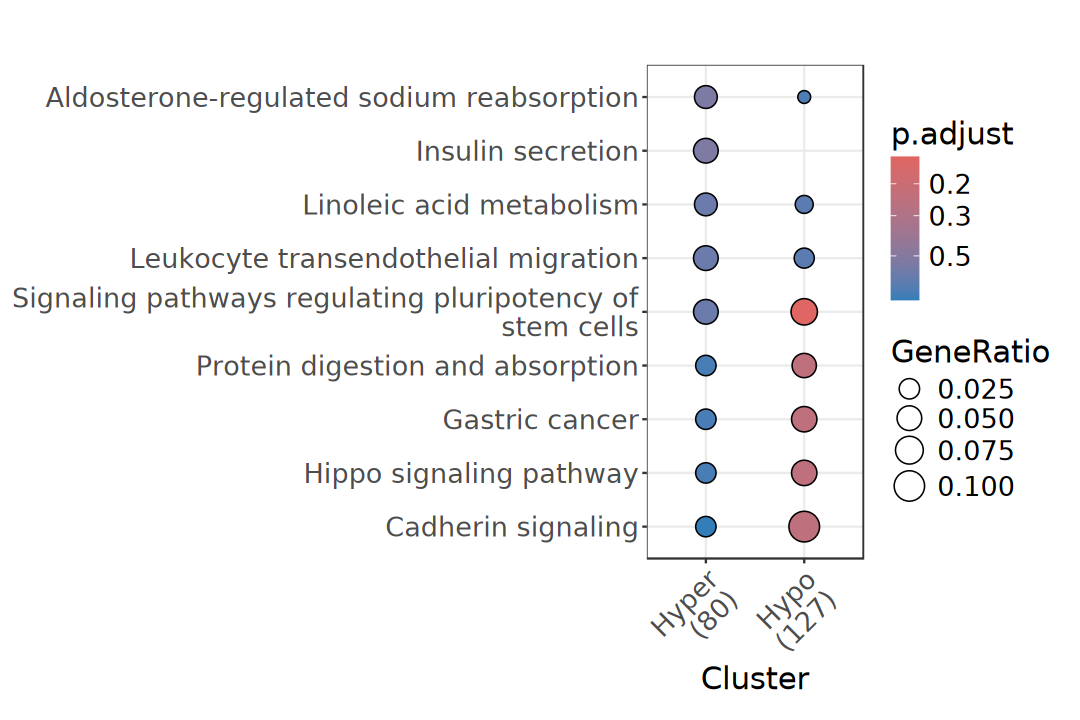

In [91]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ekegg_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 16))

# 7. DMRs Visualization

In [92]:
table(diff_dmrs_anno$geneSymbol) |> 
    sort(decreasing = TRUE) |> head()


    Etv5    Obox7   Sft2d2 Cyp3a41b    Obox1    Peg12 
       6        6        5        4        4        4 

## IGV snapshot

In [93]:
suppressPackageStartupMessages(library(Gviz))
suppressPackageStartupMessages(library(AnnotationHub))

In [94]:
genome_id = "mm9"
gene_id = "Etv5"

entrez_id <- AnnotationDbi::mapIds(
    org.Mm.eg.db, keys = gene_id, keytype = "SYMBOL", column = "ENTREZID", 
    multiVals = "first")

entrez_id

loci <- GENES[GENES$gene_id == entrez_id]
loci <- resize(loci, width = width(loci) + 10000, fix = "center") |>
    trim()
target_region <- paste0(seqnames(loci), ":", start(loci), "-", end(loci))

target_region

'select()' returned 1:1 mapping between keys and columns



Etv5 
"104156"

[1] "chr16:22376386-22444643"

In [95]:
target_region <- str_match(target_region, "([^:]+):(\\d+)-(\\d+)") |> 
    as.data.frame() |>
    transmute(
        pos = V1, chr = V2, start = as.numeric(V3), 
        end = as.numeric(V4)) |>
    column_to_rownames("pos")
target_region

,chr,start,end
,<chr>,<dbl>,<dbl>
chr16:22376386-22444643,chr16,22376386,22444643


In [96]:
ah <- AnnotationHub()
query(ah, "UCSC cytoBand track for mm9")

AnnotationHub with 1 record
# snapshotDate(): 2025-10-29
# names(): AH53179
# $dataprovider: UCSC
# $species: Mus musculus
# $rdataclass: GRanges
# $rdatadateadded: 2017-01-05
# $title: UCSC cytoBand track for mm9
# $description: Approximate location of bands seen on Giemsa-stained chromos...
# $taxonomyid: 10090
# $genome: mm9
# $sourcetype: UCSC track
# $sourceurl: http://hgdownload.cse.ucsc.edu/goldenpath/mm9/database/cytoBan...
# $sourcesize: NA
# $tags: c("cytoBand", "AHCytoBands") 
# retrieve record with 'object[["AH53179"]]' 

In [97]:
bands <- ah[["AH53179"]] |> 
    as.data.frame() |> 
    dplyr::rename(
        chrom = seqnames, chromStart = start, chromEnd = end)

loading from cache



In [98]:
idTrack <- IdeogramTrack(
    chromosome = target_region$chr, genome = genome_id, 
    name = str_to_title(target_region$chr), bands = bands,
    fontcolor = "black", fontsize = 20)
scale_bar <- GenomeAxisTrack(
    scale = 0.1, col = "black", fontcolor = "black", 
    labelPos = "above", showTitle = FALSE, fontsize = 16,
    distFromAxis = 1, lwd = 1)
coordinate <- GenomeAxisTrack(
    labelPos = "above", col = "black", fontcolor = "black", 
    exponent = 0, showTitle = FALSE, fontsize = 16, lwd = 2)

plot_list <- list(idTrack, scale_bar, coordinate)

In [99]:
signal_colors <- colorRampPalette(brewer.pal(8, "Set2"))(length(meth_list))
names(signal_colors) <- names(meth_list)

In [100]:
signal_tracks <- purrr::imap(
    meth_list, ~ Gviz::DataTrack(
        range = .x, name = .y, data = "meth", type = "histogram",
        chromosome = target_region$chr, genome = genome_id,
        showTitle = TRUE, fontsize = 12, cex.title = 1, cex.axis = 0.8,
        col.title = "black", fontcolor.title = "black",
        col.histogram = signal_colors[.y],
        fill.histogram = signal_colors[.y])
)

In [101]:
dmr_colors <- c(Hyper = "#D73027", Hypo  = "#1A9850")
diff_dmrs_anno$color <- dmr_colors[as.character(diff_dmrs_anno$result)]

In [102]:
dmr_region <- subsetByOverlaps(diff_dmrs_anno, loci, ignore.strand = TRUE)
dmr_track <- Gviz::AnnotationTrack(
    range = dmr_region, name = "DMRs", genome = genome_id,
    chromosome = target_region$chr, type = "p", 
    fill = dmr_region$color, col = dmr_region$color,
    stacking = "squish", showTitle = TRUE, fontsize = 16, 
    cex.title = 1, cex.axis = 0.8, col.title = "black", 
    fontcolor.title = "black")

In [103]:
grtrack <- GeneRegionTrack(
    txdb, genome = genome_id, chromosome = target_region$chr, 
    start = target_region$start, end = target_region$end,
    transcriptAnnotation = "symbol", showId = TRUE, geneSymbol = TRUE, 
    collapseTranscripts = "longest", fontsize = 18, 
    cex.title = 1, fontsize.group = 16, rotation.title = 0,
    name = "Gene", col = "grey", fill = "orange", 
    fontcolor.group = "black", stacking = "squish")

# gene_info <- filter(GENES, type == "gene")

# ranges(grtrack)$symbol <- gene_info$gene_name[
#     match(ranges(grtrack)$gene, gene_info$gene_id)]

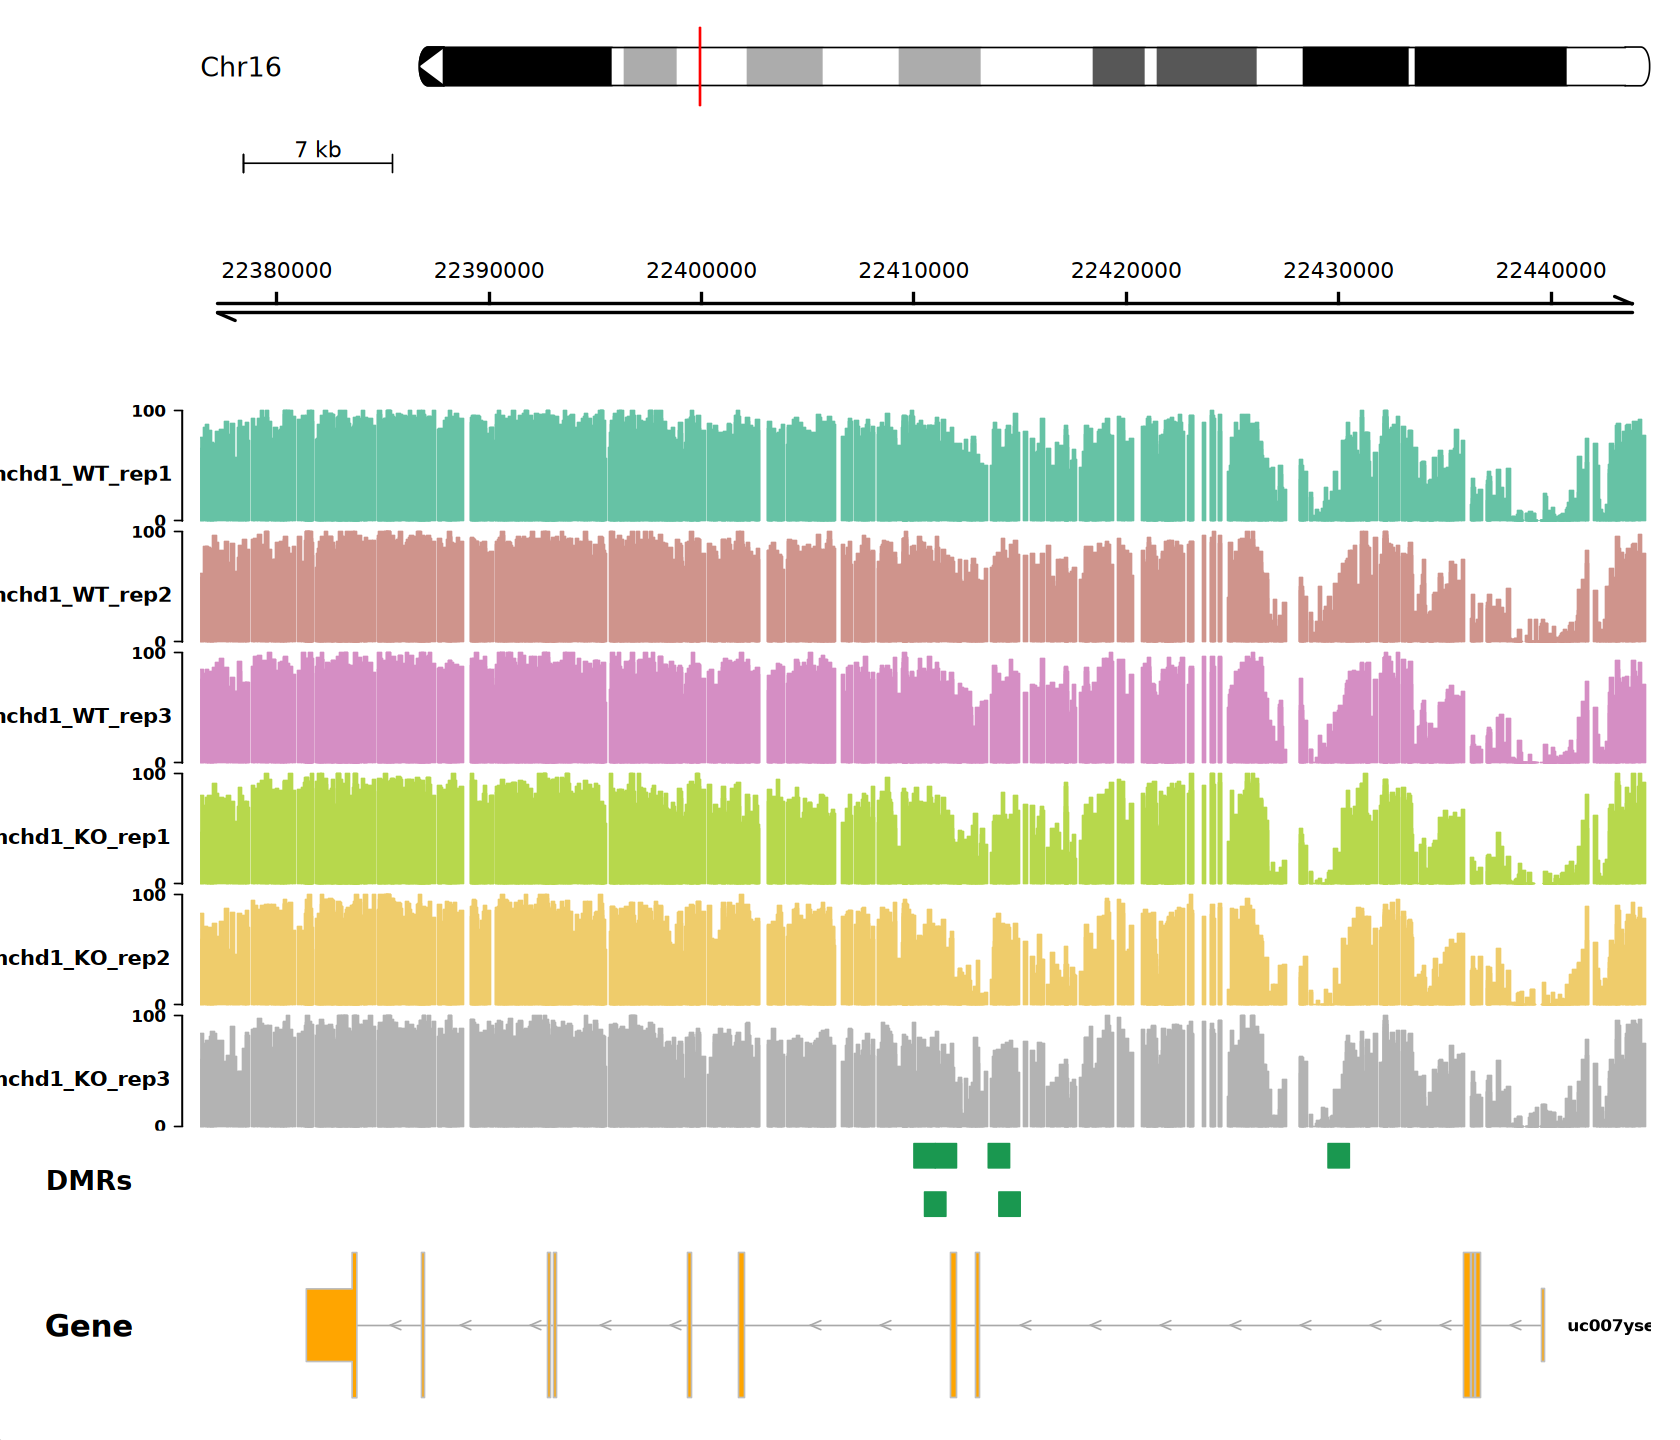

In [104]:
options(repr.plot.width = 14, repr.plot.height = 12)

plotTracks(
    trackList = c(plot_list, signal_tracks, dmr_track, grtrack), 
    chromosome = target_region$chr, 
    from = target_region$start, to = target_region$end, 
    background.title = "white", col.title = "black", col.axis = "black", 
    sizes = c(2, 2, 4, rep(2.5, length(meth_list)), 2, 4), 
    reverseStrand = FALSE, rotation.title = 0, title.width = 1, 
    just.group = "right", extend.left = 0, 
    ylim = c(0, 100), yTicksAt = c(0, 100))

# * Reference